# Load the libraries

- `numpy` supplies numerical arrays and comparisons.
- `matplotlib.pyplot` draws the channel and protocol plots.
- `QuantumCircuit` prepares the E91 entangled pair.
- `DensityMatrix` represents a quantum state, including mixed states.
- `Operator` represents the identity operation for our ideal channel.
- `state_fidelity` lets us check how closely two states agree.
- `partial_trace` checks the individual qubit states in the E91 validation.
- `depolarizing_error` provides the Qiskit Aer noise model.

Expected result: a version number and the message `Setup ready`.

In [1]:
import numpy as np
import qiskit
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit
from qiskit.quantum_info import DensityMatrix, Operator, partial_trace, state_fidelity
from qiskit_aer.noise import depolarizing_error

print("Qiskit version:", qiskit.__version__)
print("Setup ready")

Qiskit version: 2.6.2
Setup ready


## Decilcamr: I relied heavily on ChatGPT to help write the code, as I am not familiar with the Qiskit library. However, I understand what each part of the code does, and the approach and steps were based on my own ideas.

# 1) Channel

My procces of designing the channel was as follows:

1- Started with and ideal channel to test the transmission

2- Made a loss only channel, where the qubits does not arrive to Bob side

3- Made a noisy channel, where all the qubits arrive but with certain level of noise

4- Made the lossy channel that will be used int the QKD

# a) Ideal channel

This ideal channel is just my starting point for the project, I will not use it because using this will mean we will not have any error in any of the qubits we share to Bob side

## Cell 1 Define an ideal channel

An ideal channel transmits the state unchanged:

$$\rho_B = I\rho_A I^\dagger = \rho_A.$$

The 2 by 2 identity matrix represents this operation. `evolve` applies the identity to the input density matrix. This calculation models transmission; it does not do any measurement to the qubit.

In [2]:
identity = Operator(np.eye(2, dtype=complex))


def ideal_channel(rho_in):
    """Return the state after perfect single-qubit transmission."""
    return rho_in.evolve(identity)


## Cell 2 Check the X Y and Z states 

Alice prepares each state and sends it to Bob.

Test the four BB84 states, the two Y-basis states needed by the six-state protocol.

The two Z states are:

$$|0\rangle , \qquad |1\rangle$$

The two X states are:

$$|+\rangle , \qquad |-\rangle$$

The two Y states are:

$$|y_+\rangle = (|0\rangle + i|1\rangle)/\sqrt{2}, \qquad |y_-\rangle = (|0\rangle - i|1\rangle)/\sqrt{2}.$$

$i$ is the imaginary unit.



In [106]:
test_states = {
    "zero": DensityMatrix.from_label("0"),
    "one": DensityMatrix.from_label("1"),
    "plus": DensityMatrix.from_label("+"),
    "minus": DensityMatrix.from_label("-"),
    "Y plus": DensityMatrix.from_label("r"),
    "Y minus": DensityMatrix.from_label("l"),
}

for name, rho_in in test_states.items():
    rho_out = ideal_channel(rho_in)
    unchanged = np.allclose(rho_in.data, rho_out.data)
    assert unchanged and rho_out.is_valid()
    print(f"{name}: preserved = {unchanged}")

print("All ideal-channel checks passed")


zero: preserved = True
one: preserved = True
plus: preserved = True
minus: preserved = True
Y plus: preserved = True
Y minus: preserved = True
All ideal-channel checks passed


# b) Loss only channel

This channel will show the effects of losing the qubit during the transmission between Alice and Bob

## Cell 1 Convert distance to arrival probability

Let $L$ be fiber length in km and $\alpha$ attenuation in dB/km. Total loss is $A=\alpha L$ dB. The transmission probability is:

$$T=10^{-A/10}=10^{-\alpha L/10}.$$

For our single-photon model, $T$ is the probability that a photon reaches Bob's channel input. At $L=0$, this fiber model has $T=1$ , so all will be transmited at that time.




In [4]:
def transmission_probability(distance_km, alpha_db_per_km):
    """Fiber arrival probability for one emitted photon."""
    if not np.isfinite(distance_km) or distance_km < 0:
        raise ValueError("Distance must be finite and nonnegative.")
    if not np.isfinite(alpha_db_per_km) or alpha_db_per_km < 0:
        raise ValueError("Attenuation must be finite and nonnegative.")

    loss_db = alpha_db_per_km * distance_km
    return 10.0 ** (-loss_db / 10.0)


## Cell 2 Define the loss-only channel

Draw a uniform random number $u$ between 0 and 1:

- If $u<T$, the photon arrives and its density matrix is unchanged.
- Otherwise, it is lost and we return `None`.

`None` means no photon arrived. The copied object is a numerical state representation.

This will make it such that whenever I send a photon based on the random number u, it will decide either it will be transmited or not.


In [5]:
def loss_channel(rho_in, transmission, rng):
    """Return an unchanged arriving state, or None for no arrival."""
    if not np.isfinite(transmission) or not 0 <= transmission <= 1:
        raise ValueError("Transmission probability must be between 0 and 1.")

    if rng.random() < transmission:
        return rho_in.copy()
    return None


## Cell 3 Repeat for all six pure states

Each state is sent independently `n_sent` times. Loss is assumed independent of the encoded state, so every input has the same theoretical transmission probability.

For the Y states, Qiskit uses `"r"` for $(|0\rangle+i|1\rangle)/\sqrt{2}$ and `"l"` for $(|0\rangle-i|1\rangle)/\sqrt{2}$.

We count arrivals and losses, and explicitly check every arriving state. A result marked unchanged is conditional on arrival. With no arrivals, that check is not applicable.


In [107]:
distance_km = 50.0
alpha_db_per_km = 0.2
n_sent = 20000
transmission = transmission_probability(distance_km, alpha_db_per_km)


rng_many = np.random.default_rng(1)
arrival_results = []

print("State       Arrived   Lost    Arrival fraction   Arriving states unchanged")

for name, rho_in in test_states.items():
    n_arrived = 0
    for _ in range(n_sent):
        rho_out = loss_channel(rho_in, transmission, rng_many)
        if rho_out is not None:
            n_arrived = n_arrived + 1
            assert rho_out.is_valid()
            assert np.allclose(rho_in.data, rho_out.data)

    n_lost = n_sent - n_arrived
    observed = n_arrived / n_sent
    unchanged_label = "True" if n_arrived > 0 else "N/A"
    arrival_results.append((name, n_arrived, n_lost, observed))
    print(f"{name:<10} {n_arrived:>6} {n_lost:>7} {observed:>16.3%} {unchanged_label:>15}")

print(f"Theoretical arrival fraction for every state: {transmission:.3%}")


State       Arrived   Lost    Arrival fraction   Arriving states unchanged
zero         2041   17959          10.205%            True
one          1962   18038           9.810%            True
plus         2027   17973          10.135%            True
minus        1976   18024           9.880%            True
Y plus       1981   18019           9.905%            True
Y minus      1948   18052           9.740%            True
Theoretical arrival fraction for every state: 10.000%


## Cell 4 Plot transmission versus distance

The curve is theoretical transmission. The points are simulated arrivals from `n_sent` independent single-photon attempts at each distance.

The error bars show one theoretical standard deviation of the estimated arrival fraction, $\sqrt{T(1-T)/N}$. The points need not fall inside every one-standard-deviation bar about the theoretical curve.

This plot concerns channel arrivals. It is the same for all six input states under our state-independent-loss assumption.


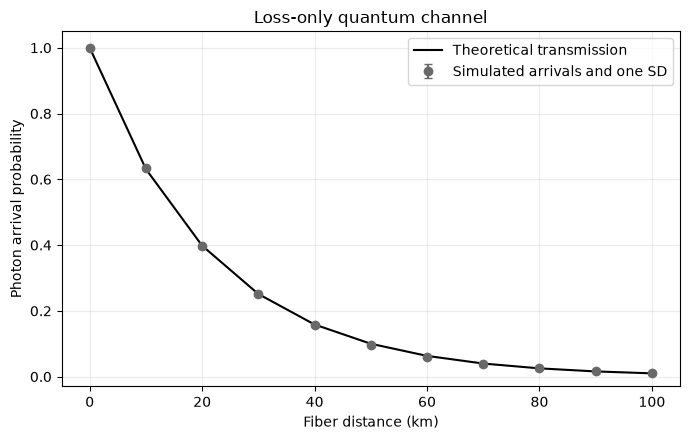

In [108]:
distances_km = np.arange(0, 101, 10)
theory = np.array([
    transmission_probability(L, alpha_db_per_km) for L in distances_km
])
rng_sweep = np.random.default_rng(1)
observed_fractions = np.array([
    np.mean(rng_sweep.random(n_sent) < T) for T in theory
])
fraction_std = np.sqrt(theory * (1 - theory) / n_sent)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(distances_km, theory, color="black", label="Theoretical transmission")
ax.errorbar(distances_km, observed_fractions, yerr=fraction_std,
            fmt="o", color="dimgray", capsize=3,
            label="Simulated arrivals and one SD")
ax.set_xlabel("Fiber distance (km)")
ax.set_ylabel("Photon arrival probability")
ax.set_title("Loss-only quantum channel")
ax.set_ylim(-0.03, 1.05)
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()

# c) Noise only

## Cell 1 Define the noise channel

Our model is:

$$\rho_{out}=(1-p)\rho_{in}+p\frac{I}{2}, \qquad 0\leq p\leq1.$$

Here $I/2$ is the completely mixed qubit state. A useful interpretation is that the channel retains the input with weight $1-p$ and replaces it by a completely random qubit with weight $p$.

**The parameter $p$ is the weight of the maximally mixed state.** A completely random qubit can still give the correct measurement result half the time. Under this model, an ideal matched-basis measurement of one of our six pure input states has error probability $p/2$.


Use $p=0.1$ as an illustrative setting, not as a measured property of a particular fiber. It is independently adjustable from distance at this stage.


`depolarizing_error(p, 1)` builds the error channel for one qubit. `.to_quantumchannel()` converts the Aer error object into a channel representation that `DensityMatrix.evolve()` can apply.

The output is a normalized density matrix. It represents the resulting state before measurement, including the mixture caused by the noise model. 


In [109]:
noise_strength = 0.1

def depolarizing_channel(rho_in, noise_strength):
    """Apply single-qubit depolarization with mixing parameter p in [0, 1]."""
    if not np.isfinite(noise_strength) or not 0 <= noise_strength <= 1:
        raise ValueError("Noise strength must be between 0 and 1.")

    noise = depolarizing_error(noise_strength, 1)
    return rho_in.evolve(noise.to_quantumchannel())


## Cell 2 Check all six states

For a pure input $|\psi\rangle$, the probability that an ideal measurement in its preparation basis returns the intended result is:

$$P_{correct}=\langle\psi|\rho_{out}|\psi\rangle
=\operatorname{Tr}(\rho_{in}\rho_{out}).$$

This overlap also equals the state fidelity when the input is pure. The wrong-outcome probability is $1-P_{correct}$. With our depolarizing convention, it equals $p/2$ for each of the six input states.

The trace expression is used here only with pure signal inputs. An arbitrary mixed state is not a single measurement projector.

This is a matched-basis diagnostic, not a complete QKD QBER calculation: we have not implemented basis selection, sifting, parameter estimation, or detector noise.


In [110]:
print("State        Fidelity    Matched-basis error probability")
for name, rho_in in test_states.items():
    rho_out = depolarizing_channel(rho_in, noise_strength)
    p_correct = float(np.trace(rho_in.data @ rho_out.data).real)
    p_error = float(np.clip(1 - p_correct, 0, 1))
    fidelity = float(state_fidelity(rho_in, rho_out))

    assert rho_out.is_valid()
    assert np.isclose(p_error, noise_strength / 2)
    assert np.isclose(fidelity, 1 - noise_strength / 2)
    print(f"{name:<11} {fidelity:>8.4f} {p_error:>23.2%}")


State        Fidelity    Matched-basis error probability
zero          0.9500                   5.00%
one           0.9500                   5.00%
plus          0.9500                   5.00%
minus         0.9500                   5.00%
Y plus        0.9500                   5.00%
Y minus       0.9500                   5.00%


## Cell 3 Sample ideal measurement outcomes

For a simple measurement check, Alice prepares zero and Bob measures in Z. Qiskit's `sample_counts` samples computational-basis outcomes from the density matrix.

Every shot represents an independently prepared copy of the same input state passed through the same noise channel. We are not repeatedly measuring one physical photon.

At $p=0.1$, the output for this input has diagonal entries 0.95 and 0.05. Therefore the expected incorrect-outcome fraction is 5 percent, with random variation around that value.

This is an ideal measurement test: there is no loss here.


In [157]:
n_shots = 20000
rho_zero_noisy = depolarizing_channel(test_states["zero"], noise_strength)
rho_zero_noisy.seed(1)
counts = rho_zero_noisy.sample_counts(n_shots)

n_wrong = int(counts.get("1", 0))
observed_error = n_wrong / n_shots
expected_error = noise_strength / 2
count_std = np.sqrt(n_shots * expected_error * (1 - expected_error))

print("Z-basis measurement counts:", {str(k): int(v) for k, v in counts.items()})
print(f"Observed error fraction: {observed_error:.2%}")
print(f"Theoretical error probability: {expected_error:.2%}")
assert sum(counts.values()) == n_shots
assert abs(n_wrong - n_shots * expected_error) <= 6 * count_std + 2


Z-basis measurement counts: {'0': 18996, '1': 1004}
Observed error fraction: 5.02%
Theoretical error probability: 5.00%


## Cell 4 Plot errors versus depolarizing strength

The theoretical line is $p/2$. At each strength, we prepare noisy zero states and sample ideal Z measurements. The markers show the observed fraction of one outcomes from `n_shots` trials.

The same expected matched-basis error applies to all six states under this isotropic noise model. We use zero and Z for the plotted sampling experiment to keep the readout simple.

This plot varies a noise parameter, not distance. It assumes every signal arrives; the loss model remains a separate component.


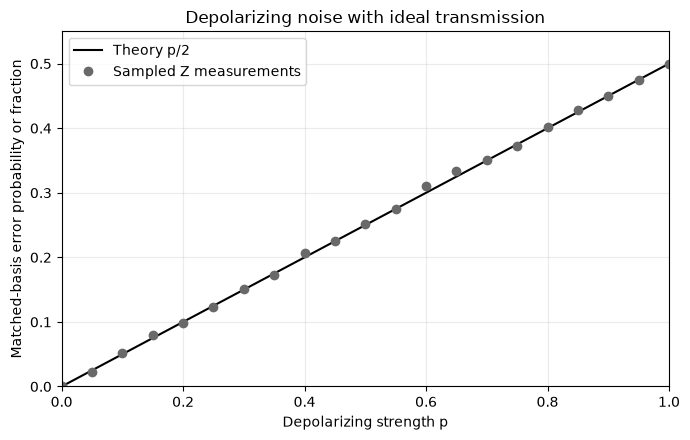

In [208]:
noise_values = np.linspace(0, 1, 21)
observed_errors = []

for index, p in enumerate(noise_values):
    rho_out = depolarizing_channel(test_states["zero"], float(p))
    rho_out.seed(700 + index)
    counts_p = rho_out.sample_counts(n_shots)
    observed_errors.append(int(counts_p.get("1", 0)) / n_shots)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(noise_values, noise_values / 2, color="black", label="Theory p/2")
ax.plot(noise_values, observed_errors, "o", color="dimgray", label="Sampled Z measurements")
ax.set_xlabel("Depolarizing strength p")
ax.set_ylabel("Matched-basis error probability or fraction")
ax.set_title("Depolarizing noise with ideal transmission")
ax.set_xlim(0, 1)
ax.set_ylim(0, 0.55)
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()

# d) Noisy lossy channel

## Cell 1 Choose distance, loss, and noise

We keep the illustrative values from before:

$$T=10^{-\alpha L/10}=10^{-0.2(50)/10}=0.1,\qquad p=0.1.$$

For 10,000 sent zero states measured in Z, the expected counts are:

| Event | Probability per sent signal | Expected count |
|---|---|---|
| Lost | $1-T=0.9$ | 18,000 |
| Arrives and is correct | $T(1-p/2)=0.095$ | 1900 |
| Arrives and is wrong | $T p/2=0.005$ | 100 |

Thus we expect 2,000 arrivals. The expected error probability **among arrivals** is $p/2=5\%$, while the probability of an arriving wrong outcome **per sent signal** is $T p/2=0.5\%$. Lost signals have no measurement outcome and are not counted as wrong bits.

The noise strength is an independently chosen example; this notebook does not assume that $p$ grows with distance.

In [209]:


transmission = transmission_probability(distance_km, alpha_db_per_km)
print(f"Arrival probability: {transmission:.1%}")
print(f"Expected arrivals: {n_sent * transmission:.1f}")
print(f"Expected wrong outcomes: {n_sent * transmission * noise_strength / 2:.1f}")
print(f"Expected error probability among arrivals: {noise_strength / 2:.1%}")

Arrival probability: 10.0%
Expected arrivals: 2000.0
Expected wrong outcomes: 100.0
Expected error probability among arrivals: 5.0%


## Cell 2 Combine the loss and noise functions

First check arrival using the existing loss function. If it returns `None`, stop: there is no qubit to measure. Otherwise, apply the existing depolarizing function and return the noisy state.

Conditional on arrival, Bob's normalized state is:

$$\rho_{Bob}=(1-p)\rho_{Alice}+pI/2.$$

Do not multiply this returned matrix by $T$: the random arrival event already represents loss. `None` is different from the quantum state $|0\rangle$.

We validate $p$ before checking loss so an invalid setting is rejected even when a signal happens to be lost. The order is a computational model for independent loss and noise, rather than a claim that real fiber disturbances happen at one specific point.

In [210]:
def noisy_lossy_channel(rho_in, transmission, noise_strength, rng):
    """Return Bob's noisy state conditional on arrival, or None for loss."""
    if not np.isfinite(noise_strength) or not 0 <= noise_strength <= 1:
        raise ValueError("Noise strength must be between 0 and 1.")

    rho_arrived = loss_channel(rho_in, transmission, rng)
    if rho_arrived is None:
        return None

    return depolarizing_channel(rho_arrived, noise_strength)

## Cell 3 Repeat transmissions and measure the arriving zero states

Alice prepares $|0\rangle$ for each trial. Bob measures each arrival in Z, so outcome 0 is correct and outcome 1 is wrong. For the received zero state, `probabilities()[1]` gives the Born probability of outcome 1. We sample that outcome using a second random generator, separate from the generator used for loss.

Each loop represents a fresh preparation and transmission. We do not repeatedly measure a single photon. The density matrix already includes the noise mixture, so do not add another random depolarizing decision.

`errors / arrivals` estimates the error probability among received signals. With zero arrivals, this ratio is undefined; the code records `np.nan` rather than claiming zero error. The seeds are only for reproducible simulation.

In [211]:
def simulate_zero_transmissions(n_sent, transmission, noise_strength, seed):
    """Channel test: send zero states, then measure every arrival in Z."""
    if not isinstance(n_sent, (int, np.integer)) or n_sent <= 0:
        raise ValueError("n_sent must be a positive integer.")

    loss_seed, measurement_seed = np.random.SeedSequence(seed).spawn(2)
    rng_loss = np.random.default_rng(loss_seed)
    rng_measurement = np.random.default_rng(measurement_seed)
    n_arrived = 0
    n_wrong = 0

    for _ in range(n_sent):
        rho_bob = noisy_lossy_channel(
            test_states["zero"], transmission, noise_strength, rng_loss
        )
        if rho_bob is None:
            continue

        n_arrived += 1
        probability_one = float(rho_bob.probabilities()[1])
        if rng_measurement.random() < probability_one:
            n_wrong += 1

    return {
        "sent": n_sent,
        "arrived": n_arrived,
        "lost": n_sent - n_arrived,
        "correct": n_arrived - n_wrong,
        "wrong": n_wrong,
        "arrival_fraction": n_arrived / n_sent,
        "error_among_arrivals": n_wrong / n_arrived if n_arrived else np.nan,
        "wrong_per_sent": n_wrong / n_sent,
    }

result = simulate_zero_transmissions(n_sent, transmission, noise_strength, seed=609)
print("Sent:", result["sent"])
print("Lost:", result["lost"])
print("Arrived:", result["arrived"])
print("Correct outcomes:", result["correct"])
print("Wrong outcomes:", result["wrong"])
print(f"Observed arrival fraction: {result['arrival_fraction']:.2%}")
if result["arrived"]:
    print(f"Observed error fraction among arrivals: {result['error_among_arrivals']:.2%}")
else:
    print("Error fraction among arrivals: undefined (no arrivals)")
print(f"Observed wrong outcomes per sent signal: {result['wrong_per_sent']:.2%}")

Sent: 20000
Lost: 18016
Arrived: 1984
Correct outcomes: 1886
Wrong outcomes: 98
Observed arrival fraction: 9.92%
Observed error fraction among arrivals: 4.94%
Observed wrong outcomes per sent signal: 0.49%


## Cell 4 Plot arrival fraction and received-signal error versus distance

Send 2,000 zero states at each distance. We hold $p$ fixed and change $T$ using distance. The left plot should follow the decreasing transmission curve. The right plot should fluctuate around $p/2$, because loss alone does not change the state of the survivors in our model.

At long distances, fewer signals survive, so the error estimate becomes less precise. A sample of zero errors does not imply a zero underlying error probability. With no arrivals the error point is omitted (`np.nan`). These loops call the combined function for each trial and may take a little time.

Error bars show one theoretical standard deviation of each fraction: $\sqrt{T(1-T)/N}$ for arrivals, and $\sqrt{q(1-q)/N_a}$ for the error fraction among arrivals, with $q=p/2$. They are not bounds that every point must satisfy.

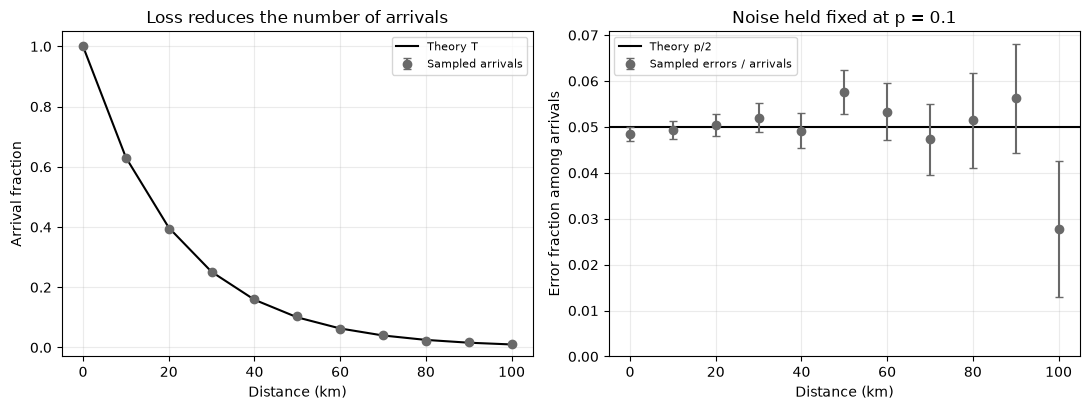

In [253]:
distances_km = np.arange(0.0, 101.0, 10.0)
n_sent_per_distance = 20000
q = noise_strength / 2
theory_transmission = np.array([
    transmission_probability(float(d), alpha_db_per_km) for d in distances_km
])
distance_results = []
for index, t in enumerate(theory_transmission):
    distance_results.append(simulate_zero_transmissions(
        n_sent_per_distance, float(t), noise_strength, seed=800 + index
    ))

arrival_fractions = np.array([r["arrival_fraction"] for r in distance_results])
error_fractions = np.array([r["error_among_arrivals"] for r in distance_results])
arrival_sd = np.sqrt(theory_transmission * (1 - theory_transmission) / n_sent_per_distance)
error_sd = np.array([
    np.sqrt(q * (1 - q) / r["arrived"]) if r["arrived"] else np.nan
    for r in distance_results
])

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].plot(distances_km, theory_transmission, color="black", label="Theory T")
axes[0].errorbar(distances_km, arrival_fractions, yerr=arrival_sd,
                 fmt="o", color="dimgray", capsize=3, label="Sampled arrivals")
axes[0].set_ylabel("Arrival fraction")
axes[0].set_ylim(-0.03, 1.05)
axes[0].set_title("Loss reduces the number of arrivals")

axes[1].axhline(q, color="black", label="Theory p/2")
axes[1].errorbar(distances_km, error_fractions, yerr=error_sd,
                 fmt="o", color="dimgray", capsize=3, label="Sampled errors / arrivals")
axes[1].set_ylabel("Error fraction among arrivals")
axes[1].set_ylim(bottom=0)
axes[1].set_title(f"Noise held fixed at p = {noise_strength:g}")
for ax in axes:
    ax.set_xlabel("Distance (km)")
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

# 2) Receiver

This part, will be bob side that will do the mersuemnt to return the deinsty matrixes that he recives to it orginal state

## Cell 1 Define what each measurement bit means

The bit is a label for one of two outcomes in the basis Bob chooses:

| Bob's basis | Bit 0 outcome | Bit 1 outcome |
|---|---|---|
| Z | $\lvert 0\rangle$ | $\lvert 1\rangle$ |
| X | $\lvert +\rangle$ | $\lvert -\rangle$ |
| Y | $\lvert y+\rangle$ | $\lvert y-\rangle$ |

Thus **bit 0 does not always mean the quantum state $|0\rangle$**. In X it labels the plus outcome. These labels are a convention that Alice and Bob must share.

Each pure-state density matrix is also a **measurement projector**: a matrix that lets us calculate the probability of that outcome. The two projectors for each basis add to the identity. They define a measurement.

In [254]:
measurement_projectors = {
    "Z": (DensityMatrix.from_label("0").data, DensityMatrix.from_label("1").data),
    "X": (DensityMatrix.from_label("+").data, DensityMatrix.from_label("-").data),
    "Y": (DensityMatrix.from_label("r").data, DensityMatrix.from_label("l").data),
}


## Cell 2 Calculate the two outcome probabilities

For a received density matrix $\rho$ and outcome projector $\Pi_b$, the Born rule gives:

$$P(b)=\operatorname{Tr}(\Pi_b\rho),\qquad b\in\{0,1\}.$$

Now we choose the projector using **Bob's measurement basis**, rather than using Alice's input state. It works for pure or mixed received states. Bob's function needs only the received state and his chosen basis.

The returned array is `[P(bit 0), P(bit 1)]`. `@` multiplies the matrices; `np.trace` adds their diagonal entries. Valid states yield real, nonnegative probabilities summing to one. We remove tiny numerical imaginary parts, clip rounding at the endpoints, and normalize the sum.

For an ideal plus state, measuring X gives `[1, 0]`; measuring Z gives `[0.5, 0.5]`. Computing these probabilities does not yet sample a random measurement result. Do not pass `None` here; Cell 3 handles loss.

In [255]:
def measurement_probabilities(rho, basis):
    """Return [P(bit 0), P(bit 1)] for a valid single-qubit state."""
    if basis not in measurement_projectors:
        raise ValueError("Basis must be 'Z', 'X', or 'Y'.")
    if not isinstance(rho, DensityMatrix):
        raise ValueError("Provide an arriving DensityMatrix, not None.")
    if rho.data.shape != (2, 2) or not rho.is_valid():
        raise ValueError("Receiver requires a valid normalized single-qubit state.")

    projector_zero, projector_one = measurement_projectors[basis]
    probabilities = np.array([
        np.trace(projector_zero @ rho.data).real,
        np.trace(projector_one @ rho.data).real,
    ], dtype=float)
    probabilities = np.clip(probabilities, 0.0, 1.0)
    return probabilities / probabilities.sum()


## Cell 3 Sample one receiver outcome

First handle `None`: there is no received qubit, so return no bit. Otherwise calculate the Born probabilities and use `rng.choice` to sample 0 or 1.


This models terminal photon detection. We only need the classical bit, so the function does not return a post-measurement quantum state. It does not modify the stored input matrix. Repeated calls in later tests represent independently prepared signals with the same state; they are not sequential measurements on one physical photon.


In [256]:
def measure_qubit(rho_received, basis, rng):
    """Ideal Z/X/Y receiver: return bit 0 or 1, or None for no arrival."""
    if basis not in measurement_projectors:
        raise ValueError("Basis must be 'Z', 'X', or 'Y'.")
    if rho_received is None:
        return None

    probabilities = measurement_probabilities(rho_received, basis)
    return int(rng.choice([0, 1], p=probabilities))

## Cell 4 Verify all three measurement bases

Check all six pure states in every basis. With no channel noise, a state measured in its own basis gives its assigned bit with probability 1. In either of the other two bases, these particular six states give 50/50 outcomes. Arbitrary states need not give 50/50 results in every other basis.

The expected probabilities below are written independently of the receiver's calculation. We also verify that each pair of projectors forms a valid measurement. These deterministic checks are the main validation.

In [257]:
# Each list contains theoretical P(bit 0) in the order Z, X, Y.
expected_p_zero = {
    "zero":    [1.0, 0.5, 0.5],
    "one":     [0.0, 0.5, 0.5],
    "plus":    [0.5, 1.0, 0.5],
    "minus":   [0.5, 0.0, 0.5],
    "Y plus":  [0.5, 0.5, 1.0],
    "Y minus": [0.5, 0.5, 0.0],
}

for projectors in measurement_projectors.values():
    assert np.allclose(projectors[0] + projectors[1], np.eye(2))
    for projector in projectors:
        assert np.allclose(projector, projector.conj().T)
        assert np.allclose(projector @ projector, projector)

print("State          P(0) in Z    P(0) in X    P(0) in Y")
for name, expected_values in expected_p_zero.items():
    measured_probabilities = []
    for basis, expected in zip(("Z", "X", "Y"), expected_values):
        probabilities = measurement_probabilities(test_states[name], basis)
        assert np.allclose(probabilities, [expected, 1 - expected])
        measured_probabilities.append(probabilities[0])
    print(f"{name:<12}" + "".join(f"{p:>14.2f}" for p in measured_probabilities))

rho_mixed = DensityMatrix(np.eye(2) / 2)
for basis in ("Z", "X", "Y"):
    assert np.allclose(measurement_probabilities(rho_mixed, basis), [0.5, 0.5])
    assert measure_qubit(None, basis, np.random.default_rng(0)) is None
print("PASS: 18 pure-state cases, mixed states, projectors, and loss handling")

State          P(0) in Z    P(0) in X    P(0) in Y
zero                  1.00          0.50          0.50
one                   0.00          0.50          0.50
plus                  0.50          1.00          0.50
minus                 0.50          0.00          0.50
Y plus                0.50          0.50          1.00
Y minus               0.50          0.50          0.00
PASS: 18 pure-state cases, mixed states, projectors, and loss handling


## Cell 5 Compare sampled outcomes in matched and different bases

For each row, prepare a fresh signal 20,000 times and call the same receiver. These examples bypass loss so the basis effect is easy to see. The noisy plus example uses our existing depolarizing channel with $p=0.1$.

| Prepared/received state | Bob's basis | Expected bit 0 fraction | Expected bit 1 fraction |
|---|---|---|---|
| Ideal plus | X | 100% | 0% |
| Ideal plus | Z | ~50% | ~50% |
| Ideal Y minus | Y | 0% | 100% |
| Noisy plus, $p=0.1$ | X | 95% | 5% |

For plus measured in X, bit 1 is an error relative to Alice's preparation. For plus measured in Z, the random outcomes are a basis effect; they do not by themselves show channel noise. In BB84 we will discard mismatched-basis rounds before estimating the key's error rate.

In [330]:
sampling_cases = [
    ("Ideal plus", test_states["plus"], "X"),
    ("Ideal plus", test_states["plus"], "Z"),
    ("Ideal Y minus", test_states["Y minus"], "Y"),
    ("Noisy plus p=0.1", depolarizing_channel(test_states["plus"], 0.1), "X"),
]
n_trials = 20000
rng_samples = np.random.default_rng(1)
print("State                 Basis    Count 0    Count 1    Fraction 1")
for name, rho_received, basis in sampling_cases:
    bits = np.array([
        measure_qubit(rho_received, basis, rng_samples) for _ in range(n_trials)
    ])
    count_one = int(np.count_nonzero(bits == 1))
    count_zero = n_trials - count_one
    print(f"{name:<21} {basis:^5} {count_zero:>10} {count_one:>10} {count_one/n_trials:>12.2%}")

State                 Basis    Count 0    Count 1    Fraction 1
Ideal plus              X        20000          0        0.00%
Ideal plus              Z         9861      10139       50.70%
Ideal Y minus           Y            0      20000      100.00%
Noisy plus p=0.1        X        18978       1022        5.11%


## Cell 6 Connect Alice, your channel, and Bob

Alice prepares plus and Bob measures X. These are matched-basis test rounds: bit 0 is correct, bit 1 is wrong, and `None` means no arrival.

We send 20,000 signals through the same loss and noise functions as before. At 50 km with $\alpha=0.2$ dB/km, $T=0.1$. With $p=0.1$, we expect about 2,000 arrivals, of which about 100 give wrong outcomes. This time our reusable receiver performs the measurement in X.



In [366]:
rho_alice = test_states["plus"]
rng_loss = np.random.default_rng(610)
rng_receiver = np.random.default_rng(611)

n_arrived = 0
n_wrong = 0

for _ in range(n_sent):
    rho_bob = noisy_lossy_channel(
        rho_alice, transmission, noise_strength, rng_loss
    )
    bob_bit = measure_qubit(rho_bob, "X", rng_receiver)

    if bob_bit is None:
        continue

    n_arrived += 1
    if bob_bit == 1:  # Plus in X should give bit 0.
        n_wrong += 1

print("Arrived:", n_arrived)
print("Lost:", n_sent - n_arrived)
print("Wrong outcomes:", n_wrong)

if n_arrived:
    print(f"Error fraction among arrivals: {n_wrong / n_arrived:.2%}")
else:
    print("Error fraction undefined: no arrivals")

Arrived: 2040
Lost: 17960
Wrong outcomes: 94
Error fraction among arrivals: 4.61%


# 3) QKD

We compare BB84, six-state, and E91 using the same 20,000 source attempts, fiber length, attenuation, depolarizing strength, and ideal detector assumptions. BB84 and six-state emit one signal qubit per attempt. E91 generates a pair at Alice, keeps one qubit locally, and sends one qubit through the same full-length link.

Classical announcements are public and authenticated: an observer may read them, but cannot impersonate Alice or Bob in this model. Authentication and an active eavesdropper are not implemented.

We simulate preparation, transmission, measurement, sifting, and public-sample error estimation. Secret-key rates are asymptotic model benchmarks. The remaining bit strings are candidates, not final secret keys. Noise strength is fixed independently of distance, so changing distance alone changes the arrival probability rather than the underlying matched-basis QBER.

# a) BB84

## Cell 1 Prepare a BB84 state from a bit and basis

| Alice's basis | Bit 0 | Bit 1 |
|---|---|---|
| Z | $\lvert0\rangle$ | $\lvert1\rangle$ |
| X | $\lvert+\rangle$ | $\lvert-\rangle$ |

`prepare_bb84(bit, basis)` selects the correct state using this table. The bit labels agree with your receiver. It returns a copy of a numerical density matrix so the stored reference state remains available. This represents a fresh physical preparation in each simulated round.

In [332]:
bb84_states = {
    "Z": (test_states["zero"], test_states["one"]),
    "X": (test_states["plus"], test_states["minus"]),
}

def prepare_bb84(bit, basis):
    """Prepare one BB84 qubit from classical bit 0/1 and basis Z/X."""
    if bit not in (0, 1):
        raise ValueError("BB84 bit must be 0 or 1.")
    if basis not in bb84_states:
        raise ValueError("BB84 basis must be 'Z' or 'X'.")
    return bb84_states[basis][int(bit)].copy()

## Cell 2 Set parameters and generate independent choices

Alice chooses a random bit and a random Z/X basis for each round. Bob independently chooses his Z/X measurement basis. Neither chooses the other's basis.

The five random streams are:  Alice's choices, Bob's choices, channel loss, measurement outcomes, and selecting the public test sample.

We send 20,000 signals at 50 km with $\alpha=0.2$ dB/km and $p=0.1$. Expected arrival probability is $T=0.1$. About 2,000 should arrive, and about half of those (1,000) should survive basis sifting. The expected matched-basis QBER is $p/2=5\%$.

The public sample will use 20% of the sifted rounds, removing them before later key processing. 

In [ ]:
n_sent = 20000
distance_km = 50.0
alpha_db_per_km = 0.2
noise_strength = 0.1
test_fraction = 0.2

if not isinstance(n_sent, (int, np.integer)) or n_sent <= 0:
    raise ValueError("n_sent must be a positive integer.")
if not np.isfinite(test_fraction) or not 0 < test_fraction < 1:
    raise ValueError("test_fraction must lie strictly between 0 and 1.")
transmission = transmission_probability(distance_km, alpha_db_per_km)
stream_seeds = np.random.SeedSequence(608).spawn(5)
rng_alice, rng_bob, rng_loss, rng_receiver, rng_test = [
    np.random.default_rng(seed) for seed in stream_seeds
]

alice_bits = rng_alice.integers(0, 2, size=n_sent)
alice_bases = rng_alice.choice(["Z", "X"], size=n_sent)
bob_bases = rng_bob.choice(["Z", "X"], size=n_sent)

print(f"Transmission probability: {transmission:.1%}")
print(f"Expected arrivals: {n_sent * transmission:.0f}")
print(f"Expected sifted rounds: {n_sent * transmission / 2:.0f}")
print(f"Expected matched-basis QBER: {noise_strength / 2:.1%}")

Transmission probability: 10.0%
Expected arrivals: 2000
Expected sifted rounds: 1000
Expected matched-basis QBER: 5.0%


## Cell 3 Transmit and measure each round

Each iteration prepares Alice's chosen state, calls your existing combined channel, and gives its result to Bob's receiver with Bob's chosen basis. The receiver returns 0, 1, or `None`.

We keep one entry per original round, including `None` for losses. This preserves alignment between Alice's records, Bob's bases, and his results. Do not remove `None` entries from Bob's list alone, or later rounds would be compared with the wrong Alice bits.

Bob's receiver is given the received state and his own basis, not Alice's bit or preparation basis. A wrong-basis measurement is still a valid bit outcome; it will be discarded later during sifting.

In [334]:
bob_bits = []
for i in range(n_sent):
    rho_alice = prepare_bb84(alice_bits[i], alice_bases[i])
    rho_bob = noisy_lossy_channel(
        rho_alice, transmission, noise_strength, rng_loss
    )
    bob_bit = measure_qubit(rho_bob, bob_bases[i], rng_receiver)
    bob_bits.append(bob_bit)

detected = np.array([bit is not None for bit in bob_bits], dtype=bool)
n_arrived = int(detected.sum())
print("Sent:", n_sent)
print("Arrived:", n_arrived)
print("Lost:", n_sent - n_arrived)

Sent: 20000
Arrived: 1984
Lost: 18016


## Cell 4 Sift: keep detected rounds with matching bases

Alice and Bob announce bases and which rounds were detected over the authenticated classical channel. They keep a round only when both conditions hold:

$$\text{detected AND }(\beta_{Alice}=\beta_{Bob}).$$

`&` combines Boolean arrays, and `np.flatnonzero` returns the positions where the combined condition is true. We use these same positions for both parties.

The resulting arrays are **sifted strings**, not final keys. Their length should be about $NT/2$. As a local simulation diagnostic, we compare them in memory to check the model's QBER. In the actual protocol they estimate QBER using only a revealed random subset (Cell 5).

In [335]:
bases_match = alice_bases == bob_bases
sifted_indices = np.flatnonzero(detected & bases_match)
alice_sifted = alice_bits[sifted_indices].copy()
bob_sifted = np.array([bob_bits[i] for i in sifted_indices], dtype=int)
n_sifted = len(sifted_indices)

print("Sifted bits per party:", n_sifted)
print("Discarded detected rounds:", n_arrived - n_sifted)
print(f"Sifted bits per sent signal: {n_sifted / n_sent:.2%}")
if n_arrived:
    print(f"Fraction of arrivals retained: {n_sifted / n_arrived:.2%}")
else:
    print("Fraction of arrivals retained: undefined (no arrivals)")

n_sifted_errors = int(np.count_nonzero(alice_sifted != bob_sifted))
qber_diagnostic = n_sifted_errors / n_sifted if n_sifted else np.nan
if n_sifted:
    print(f"Local full-string QBER diagnostic: {qber_diagnostic:.2%}")
else:
    print("Local full-string QBER diagnostic: undefined (no sifted bits)")

Sifted bits per party: 994
Discarded detected rounds: 990
Sifted bits per sent signal: 4.97%
Fraction of arrivals retained: 50.10%
Local full-string QBER diagnostic: 5.33%


## Cell 5 Reveal a random sample, estimate QBER, and discard that sample

Choose distinct positions from the sifted strings using `replace=False`. Only these test bits are treated as publicly revealed. Their disagreement fraction estimates QBER:

$$\widehat{Q}=\frac{\text{different test-bit pairs}}{\text{test-bit pairs}}.$$

Remove the test positions from both strings. The resulting `alice_remaining` and `bob_remaining` are the unrevealed candidates for later processing. They can still contain errors and are not yet secure keys.



In [336]:
remaining_mask = np.ones(n_sifted, dtype=bool)
test_positions = np.array([], dtype=int)
qber_estimate = np.nan
n_test_errors = 0

if n_sifted >= 2:
    n_test = min(n_sifted - 1, max(1, int(test_fraction * n_sifted)))
    test_positions = np.sort(rng_test.choice(n_sifted, size=n_test, replace=False))
    n_test_errors = int(np.count_nonzero(
        alice_sifted[test_positions] != bob_sifted[test_positions]
    ))
    qber_estimate = n_test_errors / n_test
    remaining_mask[test_positions] = False
    print("Publicly tested bits:", n_test)
    print("Test errors:", n_test_errors)
    print(f"Sample-estimated QBER: {qber_estimate:.2%}")
else:
    n_test = 0
    print("Insufficient sifted bits for testing and retaining a remainder.")

alice_remaining = alice_sifted[remaining_mask].copy()
bob_remaining = bob_sifted[remaining_mask].copy()
test_round_indices = sifted_indices[test_positions]
remaining_round_indices = sifted_indices[remaining_mask]
print("Unrevealed bits remaining per party:", len(alice_remaining))

Publicly tested bits: 198
Test errors: 8
Sample-estimated QBER: 4.04%
Unrevealed bits remaining per party: 796


## Cell 6 Calculate an asymptotic secret-key-rate benchmark

For ideal single-photon BB84 with one-way processing, the benchmark secret fraction per sifted bit is:

$$r_\infty=\max\{0,1-2h_2(Q)\},\qquad
h_2(Q)=-Q\log_2Q-(1-Q)\log_2(1-Q).$$

For our symmetric depolarizing model, $Q=p/2$. With uniform Z/X choices and ideal detectors, the corresponding expected benchmark **per emitted signal** is:

$$R_\infty=\frac{T}{2}\,r_\infty.$$


We print a model benchmark using $Q=p/2$, plus a sample-based plug-in estimate for comparison. The latter can fluctuate and is not a finite-key security bound. Our remaining strings have not yet undergone the processing assumed by the formula.

In [372]:
def binary_entropy(q):
    if not np.isfinite(q) or not 0 <= q <= 1:
        raise ValueError("Probability must be between 0 and 1.")
    return 0.0 if q in (0, 1) else -q*np.log2(q) - (1-q)*np.log2(1-q)


def bb84_secret_fraction(q):
    return max(0.0, 1 - 2*binary_entropy(q)) if np.isfinite(q) else np.nan


# Model prediction: include loss, sifting, and public testing.
bb84_model_bits = (
    n_sent * transmission / 2 * (1 - test_fraction)
    * bb84_secret_fraction(noise_strength / 2)
)

# Sample-based prediction: public test bits are already removed.
bb84_sample_bits = (
    len(alice_remaining) * bb84_secret_fraction(qber_estimate)
)

print(f"Model prediction: {bb84_model_bits:.0f} secret bits")
print(
    f"Sample-based prediction: {bb84_sample_bits:.0f} secret bits"
    if np.isfinite(bb84_sample_bits) else "Sample-based prediction: undefined"
)
print("Predictions assume ideal final processing; no final key was generated.")

Model prediction: 342 secret bits
Sample-based prediction: 407 secret bits
Predictions assume ideal final processing; no final key was generated.


# b) Six-state QKD

## Cell 1 Encode a bit in any of three bases

| Alice's basis | Bit 0 state | Bit 1 state |
|---|---|---|
| Z | $\lvert0\rangle$ | $\lvert1\rangle$ |
| X | $\lvert+\rangle$ | $\lvert-\rangle$ |
| Y | $\lvert y+\rangle$ | $\lvert y-\rangle$ |

The encoder now accepts Y as well as Z and X. Its bit labels agree with your receiver. This is prepare-and-measure six-state QKD: no extra Y-bit flip is needed when Alice prepares Y plus/minus and Bob measures Y. A virtual entanglement-based security proof may use a different correlation convention.

In [373]:
six_state_states = {
    "Z": (test_states["zero"], test_states["one"]),
    "X": (test_states["plus"], test_states["minus"]),
    "Y": (test_states["Y plus"], test_states["Y minus"]),
}

def prepare_six_state(bit, basis):
    """Prepare one of six pure qubit states from a bit and Z/X/Y basis."""
    if bit not in (0, 1):
        raise ValueError("Six-state bit must be 0 or 1.")
    if basis not in six_state_states:
        raise ValueError("Six-state basis must be 'Z', 'X', or 'Y'.")
    return six_state_states[basis][int(bit)].copy()

## Cell 2 Generate Alice's and Bob's random choices

Alice randomly chooses a bit and one of Z, X, Y for every attempt. Bob independently chooses one of the same three measurement bases. Each basis has probability $1/3$.

The match probability is:

$$P(\text{same basis})=3\left(\frac13\frac13\right)=\frac13.$$

With 20,000 attempts, $T=0.1$, and $p=0.1$, we expect about 2,000 arrivals and 667 sifted rounds. For comparison, BB84 expects about 1,000 sifted rounds with the same settings. The depolarizing model still gives matched-basis QBER $Q=p/2=5\%$.

The five independent random streams provide reproducibility for the simulation. They are not operational cryptographic randomness. Change the parameters here and rerun downward to start a fresh run.

In [ ]:
six_n_sent = 20000
six_distance_km = 50.0
six_alpha_db_per_km = 0.2
six_noise_strength = 0.1
six_test_fraction = 0.2

if not isinstance(six_n_sent, (int, np.integer)) or six_n_sent <= 0:
    raise ValueError("six_n_sent must be a positive integer.")
if not np.isfinite(six_test_fraction) or not 0 < six_test_fraction < 1:
    raise ValueError("six_test_fraction must lie strictly between 0 and 1.")
six_transmission = transmission_probability(six_distance_km, six_alpha_db_per_km)
six_stream_seeds = np.random.SeedSequence(708).spawn(5)
six_rng_alice, six_rng_bob, six_rng_loss, six_rng_receiver, six_rng_test = [
    np.random.default_rng(seed) for seed in six_stream_seeds
]

six_alice_bits = six_rng_alice.integers(0, 2, size=six_n_sent)
six_alice_bases = six_rng_alice.choice(["Z", "X", "Y"], size=six_n_sent)
six_bob_bases = six_rng_bob.choice(["Z", "X", "Y"], size=six_n_sent)

print(f"Transmission probability: {six_transmission:.1%}")
print(f"Expected arrivals: {six_n_sent * six_transmission:.1f}")
print(f"Expected sifted rounds: {six_n_sent * six_transmission / 3:.1f}")
print(f"Expected matched-basis QBER: {six_noise_strength / 2:.1%}")

Transmission probability: 10.0%
Expected arrivals: 2000.0
Expected sifted rounds: 666.7
Expected matched-basis QBER: 5.0%


## Cell 3 Transmit and measure

The structure is the same as BB84. Prepare Alice's selected state, send it through your combined channel, and measure using Bob's basis. `None` means loss; bit 0 is a valid measurement result. Keep one entry per original round to preserve alignment.

The existing `measure_qubit` already supports Y, so the receiver needs no modification. It receives neither Alice's original bit nor her preparation basis.

In [375]:
six_bob_bits = []
for six_i in range(six_n_sent):
    six_rho_alice = prepare_six_state(six_alice_bits[six_i], six_alice_bases[six_i])
    six_rho_bob = noisy_lossy_channel(
        six_rho_alice, six_transmission, six_noise_strength, six_rng_loss
    )
    six_bob_bit = measure_qubit(six_rho_bob, six_bob_bases[six_i], six_rng_receiver)
    six_bob_bits.append(six_bob_bit)

six_detected = np.array([bit is not None for bit in six_bob_bits], dtype=bool)
six_n_arrived = int(six_detected.sum())
print("Sent:", six_n_sent)
print("Arrived:", six_n_arrived)
print("Lost:", six_n_sent - six_n_arrived)

Sent: 20000
Arrived: 2010
Lost: 17990


## Cell 4 Sift and inspect the three basis error rates

Keep detected rounds where Alice and Bob used the same basis. Approximately one-third of arrivals should remain. This is the **sifting efficiency**, separate from the arrival fraction and from the secret fraction.

For each basis, calculate the disagreement fraction on its retained rounds. These full-string comparisons are local simulation diagnostics. In the protocol the parties reveal only a random sample, handled in Cell 5. A basis with no retained rounds has undefined QBER, represented by `np.nan`, not zero.

In [376]:
six_bases_match = six_alice_bases == six_bob_bases
six_sifted_indices = np.flatnonzero(six_detected & six_bases_match)
six_alice_sifted = six_alice_bits[six_sifted_indices].copy()
six_bob_sifted = np.array([six_bob_bits[i] for i in six_sifted_indices], dtype=int)
six_sifted_bases = six_alice_bases[six_sifted_indices]
six_n_sifted = len(six_sifted_indices)
six_n_errors = int(np.count_nonzero(six_alice_sifted != six_bob_sifted))
six_qber_diagnostic = six_n_errors / six_n_sifted if six_n_sifted else np.nan

print("Sifted rounds:", six_n_sifted)
print(f"Sifted rounds per sent signal: {six_n_sifted / six_n_sent:.2%}")
if six_n_arrived:
    print(f"Fraction of arrivals retained: {six_n_sifted / six_n_arrived:.2%}")
else:
    print("Fraction of arrivals retained: undefined (no arrivals)")
print("Basis     Sifted count     Diagnostic QBER")
six_qber_by_basis = {}
for six_basis in ("Z", "X", "Y"):
    six_basis_mask = six_sifted_bases == six_basis
    six_basis_count = int(six_basis_mask.sum())
    six_basis_errors = int(np.count_nonzero(
        six_alice_sifted[six_basis_mask] != six_bob_sifted[six_basis_mask]
    ))
    six_qber_by_basis[six_basis] = (
        six_basis_errors / six_basis_count if six_basis_count else np.nan
    )
    six_qber_text = f"{six_qber_by_basis[six_basis]:.2%}" if six_basis_count else "undefined"
    print(f"{six_basis:^5} {six_basis_count:>16} {six_qber_text:>19}")
if six_n_sifted:
    print(f"Pooled full-string diagnostic QBER: {six_qber_diagnostic:.2%}")
else:
    print("Pooled full-string diagnostic QBER: undefined (no sifted rounds)")

Sifted rounds: 671
Sifted rounds per sent signal: 3.36%
Fraction of arrivals retained: 33.38%
Basis     Sifted count     Diagnostic QBER
  Z                237               2.53%
  X                226               4.87%
  Y                208               6.73%
Pooled full-string diagnostic QBER: 4.62%


## Cell 5 Publicly test a random subset in each basis

Sample without replacement within each basis, so the public test includes Z, X, and Y whenever that basis has at least two sifted rounds. Reveal about 20% of each basis's rounds and remove them from the unrevealed candidates. We leave at least one candidate in each tested basis.

Sampling within each basis makes the three error estimates visible. If a basis has fewer than two sifted rounds, it cannot both contribute a public test bit and retain a candidate; its test QBER is undefined. This does not invalidate the other basis samples, but it prevents a full three-basis parameter characterization for that finite run.


In [377]:
six_test_groups = []
six_test_qber_by_basis = {}
print("Basis     Public test bits     Test errors     Test QBER")
for six_basis in ("Z", "X", "Y"):
    six_positions = np.flatnonzero(six_sifted_bases == six_basis)
    if len(six_positions) < 2:
        six_test_qber_by_basis[six_basis] = np.nan
        print(f"{six_basis:^5} {0:>20} {0:>15} {'undefined':>13}")
        continue
    six_sample_size = min(
        len(six_positions) - 1,
        max(1, int(six_test_fraction * len(six_positions)))
    )
    six_selected = six_rng_test.choice(six_positions, size=six_sample_size, replace=False)
    six_sample_errors = int(np.count_nonzero(
        six_alice_sifted[six_selected] != six_bob_sifted[six_selected]
    ))
    six_test_qber_by_basis[six_basis] = six_sample_errors / six_sample_size
    six_test_groups.append(six_selected)
    print(f"{six_basis:^5} {six_sample_size:>20} {six_sample_errors:>15} "
          f"{six_test_qber_by_basis[six_basis]:>13.2%}")

six_test_positions = (
    np.sort(np.concatenate(six_test_groups)) if six_test_groups else np.array([], dtype=int)
)
six_n_test = len(six_test_positions)
six_test_errors = int(np.count_nonzero(
    six_alice_sifted[six_test_positions] != six_bob_sifted[six_test_positions]
))
six_qber_estimate = six_test_errors / six_n_test if six_n_test else np.nan
six_remaining_mask = np.ones(six_n_sifted, dtype=bool)
six_remaining_mask[six_test_positions] = False
six_alice_remaining = six_alice_sifted[six_remaining_mask].copy()
six_bob_remaining = six_bob_sifted[six_remaining_mask].copy()
six_test_round_indices = six_sifted_indices[six_test_positions]
six_remaining_round_indices = six_sifted_indices[six_remaining_mask]

print("Total publicly tested rounds:", six_n_test)
if six_n_test:
    print(f"Pooled test QBER: {six_qber_estimate:.2%}")
else:
    print("Pooled test QBER: undefined (no test rounds)")
print("Unrevealed candidates per party:", len(six_alice_remaining))

Basis     Public test bits     Test errors     Test QBER
  Z                     47               1         2.13%
  X                     45               2         4.44%
  Y                     41               1         2.44%
Total publicly tested rounds: 133
Pooled test QBER: 3.01%
Unrevealed candidates per party: 538


## Cell 6 Six-state asymptotic secret-key-rate benchmark

With ideal one-way processing, six-state uses the entropy of four Bell-state probabilities. For our symmetric model they are $\lambda=(1-3Q/2,Q/2,Q/2,Q/2)$ and the secret fraction is $r_6=\max(0,1-H_4(\lambda))$, with $H_4=-\sum_j\lambda_j\log_2\lambda_j$.

Here $Q=p/2$, so equivalently $\lambda=(1-3p/4,p/4,p/4,p/4)$. These are security-analysis probabilities, not the four signal-preparation probabilities. The simulated protocol still prepares single-qubit states.

Uniform basis choices give the rate $R_6=(T/3)r_6$ per emitted signal. BB84's comparable model benchmark is $(T/2)\max(0,1-2h_2(Q))$. Six-state can have a larger secret fraction per sifted bit while yielding fewer bits per emitted signal because of sifting.



In [401]:
def six_shannon_entropy(probabilities):
    """Shannon entropy in bits for a normalized probability vector."""
    probabilities = np.asarray(probabilities, dtype=float)
    if (probabilities.ndim != 1 or not np.all(np.isfinite(probabilities))
            or np.any(probabilities < 0) or not np.isclose(probabilities.sum(), 1)):
        raise ValueError("Provide a normalized vector of nonnegative probabilities.")
    positive = probabilities[probabilities > 0]
    return float(-np.sum(positive * np.log2(positive)))

def six_secret_fraction(q):
    """One-way asymptotic fraction for symmetric depolarizing QBER in [0, 0.5]."""
    if not np.isfinite(q) or not 0 <= q <= 0.5:
        raise ValueError("This symmetric depolarizing model requires QBER in [0, 0.5].")
    bell_probabilities = [1 - 1.5 * q, q / 2, q / 2, q / 2]
    return max(0.0, 1 - six_shannon_entropy(bell_probabilities))

six_qber_model = six_noise_strength / 2
six_fraction_model = six_secret_fraction(six_qber_model)
six_rate_model = six_transmission * six_fraction_model / 3
six_bb84_fraction_model = max(0.0, 1 - 2 * six_shannon_entropy(
    [six_qber_model, 1 - six_qber_model]
))
six_bb84_rate_model = six_transmission * six_bb84_fraction_model / 2

print(f"Model QBER: {six_qber_model:.2%}")
print("Model-only comparison at the same transmission and noise:")
print("Protocol       Sift fraction     Secret bits/sifted bit     Secret bits/sent signal")
print(f"BB84 theory    {0.5:>13.2%} {six_bb84_fraction_model:>26.4f} {six_bb84_rate_model:>27.6f}")
print(f"Six-state      {1/3:>13.2%} {six_fraction_model:>26.4f} {six_rate_model:>27.6f}")

six_has_all_test_bases = all(np.isfinite(q) for q in six_test_qber_by_basis.values())
if six_has_all_test_bases and 0 <= six_qber_estimate <= 0.5:
    six_fraction_plugin = six_secret_fraction(six_qber_estimate)
    six_rate_plugin = (six_n_sifted / six_n_sent) * six_fraction_plugin
    print(f"Symmetric-model sample plug-in rate: {six_rate_plugin:.6f} bits per sent signal")
else:
    six_rate_plugin = np.nan
    print("Sample plug-in rate: undefined (insufficient samples or outside model range)")

Model QBER: 5.00%
Model-only comparison at the same transmission and noise:
Protocol       Sift fraction     Secret bits/sifted bit     Secret bits/sent signal
BB84 theory           50.00%                     0.4272                    0.021360
Six-state             33.33%                     0.4968                    0.016561
Symmetric-model sample plug-in rate: 0.022252 bits per sent signal


# c) E91

E91 uses entangled pairs. Unlike BB84 and six-state, Alice does not choose a bit to encode: Alice's and Bob's bits arise from measurements of their respective qubits.

Each attempt starts with a fresh $\lvert\Phi^+\rangle$ pair at Alice. She keeps A and physically sends B through the fiber. Entanglement does not transport the qubit. The pair is not assumed to be shared before transmission. Alice's local detector is ideal; a usable coincidence therefore requires Bob's qubit to arrive.

We estimate key-round QBER and, on separate rounds, calculate the CHSH statistic S. A Bell violation checks the correlations under the model assumptions; it does not by itself produce a secure key.

## Cell 1 Prepare the shared Bell pair

$$\lvert\Phi^+\rangle_{AB}=\frac{\lvert00\rangle+\lvert11\rangle}{\sqrt2}.$$

Apply a Hadamard to Alice's qubit and a CNOT from Alice to Bob. Alice does not choose a secret bit to encode here: her random bit will be a measurement outcome correlated with Bob's.

**Ordering convention:** Qiskit's rightmost qubit is q0. We set **A = q1, B = q0**, so matrix entries use the order $\lvert A B\rangle$. A tensor product is written `np.kron(A_matrix, B_matrix)`. Noise on B uses `qargs=[0]`.

The stored source matrix describes independently prepared pairs with identical preparation. Each later transmission is a fresh pair, not repeated measurement of the same physical pair.

Qiskit numbers the two qubits 0 and 1. Bob is the first by index (q0), but is written on the right in the ket. The preparation steps are:

$$\lvert00\rangle\xrightarrow{H_A}\frac{\lvert00\rangle+\lvert10\rangle}{\sqrt2}\xrightarrow{\mathrm{CNOT}_{A\to B}}\frac{\lvert00\rangle+\lvert11\rangle}{\sqrt2}.$$

The matrix is 4 by 4 because the joint basis is $\lvert00\rangle,\lvert01\rangle,\lvert10\rangle,\lvert11\rangle$. Bob's qubit alone is $I_2/2$; the useful correlations are in the joint state. The following cells reuse this reference preparation to represent fresh physical pairs.

In [379]:
def e91_prepare_pair():
    """Prepare Phi-plus with Alice=q1 and Bob=q0."""
    circuit = QuantumCircuit(2)
    circuit.h(1)
    circuit.cx(1, 0)
    return DensityMatrix.from_instruction(circuit)

e91_rho_source = e91_prepare_pair()

## Cell 2 Define the measurement settings and joint probabilities

The lecture uses $D_+=(Z+X)/\sqrt2$ and $D_-=(Z-X)/\sqrt2$. Alice chooses from **Z, X, D+**; Bob chooses from **D+, D-, X**.

For any of these observables M, bit 0 labels its +1 eigenvalue and bit 1 labels its -1 eigenvalue. Their projectors are $(I+M)/2$ and $(I-M)/2$. For settings x,y the joint probability is:

$$P(a,b\mid x,y)=\operatorname{Tr}[(\Pi_a^x\otimes\Pi_b^y)\rho_{AB}].$$

The four array entries are `[P(00), P(01), P(10), P(11)]`. We need the joint state: measuring each reduced state independently would lose the correlations.

This simulates **two local measurements** using their joint distribution. It is not a joint Bell-state measurement; no signal is sent between the measurement devices to create the correlations.

Z, X, D+, and D- are measurement observables, not density matrices. The two projectors for each observable M are $\Pi_0=(I+M)/2$ and $\Pi_1=(I-M)/2$. For Z, these are the familiar $\lvert0\rangle\langle0\rvert$ and $\lvert1\rangle\langle1\rvert$.

`np.kron(projector_a, projector_b)` forms the product projector, `@` multiplies matrices, and `np.trace` calculates its probability. The nested loops use Alice's bit first, giving the order 00, 01, 10, 11. `np.clip` and normalization handle numerical rounding. This cell calculates probabilities; Cell 4 below samples the outcomes.

In [380]:
e91_identity = np.eye(2, dtype=complex)
e91_z = np.array([[1, 0], [0, -1]], dtype=complex)
e91_x = np.array([[0, 1], [1, 0]], dtype=complex)
e91_observables = {
    "Z": e91_z,
    "X": e91_x,
    "D+": (e91_z + e91_x) / np.sqrt(2),
    "D-": (e91_z - e91_x) / np.sqrt(2),
}
e91_projectors = {
    setting: ((e91_identity + observable) / 2, (e91_identity - observable) / 2)
    for setting, observable in e91_observables.items()
}

def e91_joint_probabilities(rho_ab, alice_setting, bob_setting):
    """Return probabilities of 00, 01, 10, 11 for two local measurements."""
    if alice_setting not in e91_projectors or bob_setting not in e91_projectors:
        raise ValueError("Unknown E91 measurement setting.")
    if (not isinstance(rho_ab, DensityMatrix) or rho_ab.dims() != (2, 2)
            or not rho_ab.is_valid()):
        raise ValueError("Provide a valid normalized two-qubit density matrix.")
    probabilities = np.array([
        np.trace(np.kron(projector_a, projector_b) @ rho_ab.data).real
        for projector_a in e91_projectors[alice_setting]
        for projector_b in e91_projectors[bob_setting]
    ])
    probabilities = np.clip(probabilities, 0.0, 1.0)
    return probabilities / probabilities.sum()

print("Ideal X/X probabilities:", e91_joint_probabilities(e91_rho_source, "X", "X"))
print("Ideal Z/D+ probabilities:", e91_joint_probabilities(e91_rho_source, "Z", "D+"))

Ideal X/X probabilities: [0.5 0.  0.  0.5]
Ideal Z/D+ probabilities: [0.4267767 0.0732233 0.0732233 0.4267767]


## Cell 3 Apply loss and noise to Bob's half

Reuse the loss decision, then apply the same one-qubit depolarizing channel specifically to B. Conditional on arrival, for our Bell input the result is:

$$\rho_{AB}'=(1-p)\lvert\Phi^+\rangle\langle\Phi^+\rvert+pI_4/4.$$

`qargs=[0]` selects Bob=q0 in the joint matrix. We do not depolarize both qubits or apply a two-qubit depolarizing error. In particular, the local operation on B leaves Alice's reduced state unchanged for every input.

`None` means no usable coincidence because Bob's photon was lost. Surviving states remain normalized; T is not multiplied into their density matrices. As before, choosing loss first is a simulation arrangement for independent processes.

Compare this with the previous one-qubit channel $\rho'=(1-p)\rho+pI_2/2$. For a general two-qubit input, Bob-only depolarization is:

$$\rho'_{AB}=(1-p)\rho_{AB}+p\left(\rho_A\otimes I_2/2\right).$$

Our Bell pair has $\rho_A=I_2/2$, so the second term becomes $pI_4/4$. This simplified expression is specific to the Bell input; it does not mean we applied noise to Alice. Her individual state remains unchanged while the correlations weaken. The function still returns the whole joint matrix so the receiver can retain those correlations.

In [381]:
def e91_pair_channel(rho_ab, transmission, noise_strength, rng):
    """Model Bob's loss and local depolarization; Alice=q1, Bob=q0."""
    if not np.isfinite(noise_strength) or not 0 <= noise_strength <= 1:
        raise ValueError("Noise strength must be between 0 and 1.")
    if (not isinstance(rho_ab, DensityMatrix) or rho_ab.dims() != (2, 2)
            or not rho_ab.is_valid()):
        raise ValueError("Provide a valid normalized two-qubit state.")
    rho_arrived = loss_channel(rho_ab, transmission, rng)
    if rho_arrived is None:
        return None
    noise = depolarizing_error(noise_strength, 1).to_quantumchannel()
    return rho_arrived.evolve(noise, qargs=[0])

## Cell 4 Sample correlated measurement bits

Sample one of the four joint outcomes and split it into Alice's and Bob's bits. `divmod(outcome, 2)` maps 0,1,2,3 to (0,0),(0,1),(1,0),(1,1). If Bob's signal was lost, return `(None, None)` to mark that this notebook records no usable coincidence outcomes for the round. We do not need Alice's otherwise unused local measurement outcome for a lost round.

The function returns only terminal classical outcomes, not a post-measurement pair. Local marginals remain random even when the joint outcomes are correlated; this does not enable signaling.

`rng.choice(4, p=probabilities)` selects an outcome index 0, 1, 2, or 3 with its Born probability. `divmod(outcome, 2)` converts that index into the two classical bits. For example, index 2 gives `(1, 0)`: Alice gets 1 and Bob gets 0. The function does not return a collapsed quantum state because this model uses terminal measurements.

In [382]:
def e91_measure_pair(rho_ab, alice_setting, bob_setting, rng):
    """Return correlated local bits, or (None, None) for no coincidence."""
    if alice_setting not in e91_projectors or bob_setting not in e91_projectors:
        raise ValueError("Unknown E91 measurement setting.")
    if rho_ab is None:
        return None, None
    probabilities = e91_joint_probabilities(rho_ab, alice_setting, bob_setting)
    outcome = int(rng.choice(4, p=probabilities))
    return divmod(outcome, 2)

## Cell 5 Choose parameters and random settings

Each of the three local settings is equally likely. Of detected pairs, the lecture arrangement assigns:

| Round category | Setting pairs (Alice, Bob) | Expected fraction |
|---|---|---|
| Key | (X, X), (D+, D+) | 2/9 |
| CHSH test | (Z, D+), (Z, D-), (X, D+), (X, D-) | 4/9 |
| Discard | The other three combinations | 3/9 |

These groups are disjoint. In the ideal Phi-plus state, key-setting outcomes are equal; no bit flip is needed. Under Bob-only depolarization, key-round QBER is $p/2$ and the expected CHSH value is $2\sqrt2(1-p)$.

Use the same 20,000 source trials, 50 km fiber, 0.2 dB/km attenuation, and $p=0.1$ as before. The source trial is now an entangled pair rather than a single prepared qubit. Rerun from this cell when changing parameters.

The public-test fraction is applied later to the key rounds only. It is separate from the 4/9 of detected pairs assigned to CHSH. The arrays created here contain random measurement settings, not measurement outcomes. The five seeded random streams make the run reproducible.

In [383]:
e91_n_pairs = 20_000
e91_distance_km = 50.0
e91_alpha_db_per_km = 0.2
e91_noise_strength = 0.1
e91_public_test_fraction = 0.2

if not isinstance(e91_n_pairs, (int, np.integer)) or e91_n_pairs <= 0:
    raise ValueError("e91_n_pairs must be a positive integer.")
if not np.isfinite(e91_public_test_fraction) or not 0 < e91_public_test_fraction < 1:
    raise ValueError("Public test fraction must lie strictly between 0 and 1.")
e91_transmission = transmission_probability(e91_distance_km, e91_alpha_db_per_km)
e91_stream_seeds = np.random.SeedSequence(810).spawn(5)
e91_rng_alice, e91_rng_bob, e91_rng_loss, e91_rng_measurement, e91_rng_test = [
    np.random.default_rng(seed) for seed in e91_stream_seeds
]
e91_alice_choices = e91_rng_alice.choice(["Z", "X", "D+"], size=e91_n_pairs)
e91_bob_choices = e91_rng_bob.choice(["D+", "D-", "X"], size=e91_n_pairs)
e91_chsh_settings = (("Z", "D+"), ("Z", "D-"), ("X", "D+"), ("X", "D-"))

print(f"Expected coincidences: {e91_n_pairs * e91_transmission:.1f}")
print(f"Expected key rounds before public sampling: {e91_n_pairs * e91_transmission * 2/9:.1f}")
print(f"Expected CHSH rounds: {e91_n_pairs * e91_transmission * 4/9:.1f}")
print(f"Expected key-round QBER: {e91_noise_strength/2:.1%}")
print(f"Expected CHSH S: {2*np.sqrt(2)*(1-e91_noise_strength):.4f}")

Expected coincidences: 2000.0
Expected key rounds before public sampling: 444.4
Expected CHSH rounds: 888.9
Expected key-round QBER: 5.0%
Expected CHSH S: 2.5456


## Cell 6 Distribute pairs and measure

Each attempt represents a freshly prepared pair with the same ideal source state. The pair channel acts on B only. We record the two correlated outcomes when Bob's half arrives and `(None, None)` otherwise. Settings are selected independently of the loss and measurement randomness.

Here the density matrix is used to simulate both local measurements. Alice and Bob do not access a shared density-matrix object in a physical implementation; each holds a local qubit and records a local outcome.

The Boolean masks sort detected rounds by settings: `&` means AND and `|` means OR. `np.isin` checks membership in a list of settings; `np.flatnonzero` returns the selected original round positions. We retain key rounds based on settings and detection, never based on whether the measured bits agree. Sifting efficiency is key rounds divided by detected coincidences, not divided by all generated pairs.

In [384]:
e91_alice_bits = []
e91_bob_bits = []
for e91_i in range(e91_n_pairs):
    e91_rho_arrived = e91_pair_channel(
        e91_rho_source, e91_transmission, e91_noise_strength, e91_rng_loss
    )
    e91_a, e91_b = e91_measure_pair(
        e91_rho_arrived, e91_alice_choices[e91_i], e91_bob_choices[e91_i],
        e91_rng_measurement
    )
    e91_alice_bits.append(e91_a)
    e91_bob_bits.append(e91_b)

e91_detected = np.array([bit is not None for bit in e91_bob_bits], dtype=bool)
e91_n_detected = int(e91_detected.sum())
e91_key_mask = e91_detected & (
    ((e91_alice_choices == "X") & (e91_bob_choices == "X")) |
    ((e91_alice_choices == "D+") & (e91_bob_choices == "D+"))
)
e91_chsh_mask = e91_detected & np.isin(e91_alice_choices, ["Z", "X"]) & np.isin(e91_bob_choices, ["D+", "D-"])
e91_key_indices = np.flatnonzero(e91_key_mask)
e91_n_key = len(e91_key_indices)
e91_n_chsh = int(e91_chsh_mask.sum())

print("Generated pairs:", e91_n_pairs)
print("Detected coincidences:", e91_n_detected)
print("Lost Bob photons:", e91_n_pairs - e91_n_detected)
print("Key rounds before public testing:", e91_n_key)
print("CHSH rounds:", e91_n_chsh)
print("Other detected rounds discarded:", e91_n_detected - e91_n_key - e91_n_chsh)
if e91_n_detected:
    print(f"Key sifting efficiency: {e91_n_key/e91_n_detected:.2%}")
else:
    print("Key sifting efficiency: undefined (no coincidences)")

Generated pairs: 20000
Detected coincidences: 1937
Lost Bob photons: 18063
Key rounds before public testing: 450
CHSH rounds: 864
Other detected rounds discarded: 623
Key sifting efficiency: 23.23%


## Cell 7 Estimate key-round QBER from a public sample

Only the two key-setting groups supply candidate bits. Compute a local full-string diagnostic, then publicly sample about 20% from each key-setting group and remove those positions. This public test is **separate from CHSH**. CHSH uses its own disjoint measurement-setting groups.

The pooled public disagreement fraction estimates key QBER under our symmetric noise model. A group with fewer than two key rounds cannot both provide a test sample and retain a remainder, so its estimate is undefined. We do not infer zero errors from no data.

The remaining candidate strings are kept only for bookkeeping. The project currently estimates rates rather than generating final secret keys. The source is Phi-plus, so matched X/X and D+/D+ outcomes should be equal; retaining only equal bit pairs would incorrectly hide channel errors.

The diagnostic compares all key-round bits privately in the simulation. In the protocol, only the randomly selected sample is compared publicly:

$$\widehat Q=\frac{\text{disagreements in the public key sample}}{\text{publicly tested key rounds}}.$$

Revealed bits are removed from both candidates. A finite sample can differ from the full-string diagnostic. Under the specified symmetric depolarizing model, the underlying key-round QBER is $p/2$.

In [385]:
e91_alice_key = np.array([e91_alice_bits[i] for i in e91_key_indices], dtype=int)
e91_bob_key = np.array([e91_bob_bits[i] for i in e91_key_indices], dtype=int)
e91_key_group = e91_alice_choices[e91_key_indices]
e91_n_key_errors = int(np.count_nonzero(e91_alice_key != e91_bob_key))
e91_qber_diagnostic = e91_n_key_errors/e91_n_key if e91_n_key else np.nan
e91_test_groups = []
e91_test_qber_by_setting = {}
print("Key setting    Public test bits    Test QBER")
for e91_setting in ("X", "D+"):
    e91_positions = np.flatnonzero(e91_key_group == e91_setting)
    if len(e91_positions) < 2:
        e91_test_qber_by_setting[e91_setting] = np.nan
        print(f"{e91_setting:^11} {0:>19} {'undefined':>12}")
        continue
    e91_sample_size = min(len(e91_positions)-1, max(1, int(e91_public_test_fraction*len(e91_positions))))
    e91_sample = e91_rng_test.choice(e91_positions, size=e91_sample_size, replace=False)
    e91_errors = int(np.count_nonzero(e91_alice_key[e91_sample] != e91_bob_key[e91_sample]))
    e91_test_qber_by_setting[e91_setting] = e91_errors/e91_sample_size
    e91_test_groups.append(e91_sample)
    print(f"{e91_setting:^11} {e91_sample_size:>19} {e91_errors/e91_sample_size:>12.2%}")

e91_test_positions = np.sort(np.concatenate(e91_test_groups)) if e91_test_groups else np.array([],dtype=int)
e91_n_test = len(e91_test_positions)
e91_test_errors = int(np.count_nonzero(e91_alice_key[e91_test_positions] != e91_bob_key[e91_test_positions]))
e91_qber_estimate = e91_test_errors/e91_n_test if e91_n_test else np.nan
e91_remaining_mask = np.ones(e91_n_key,dtype=bool)
e91_remaining_mask[e91_test_positions] = False
e91_alice_remaining = e91_alice_key[e91_remaining_mask].copy()
e91_bob_remaining = e91_bob_key[e91_remaining_mask].copy()
e91_public_test_rounds = e91_key_indices[e91_test_positions]
e91_remaining_rounds = e91_key_indices[e91_remaining_mask]

if e91_n_key:
    print(f"Full-key local diagnostic QBER: {e91_qber_diagnostic:.2%}")
else:
    print("Full-key local diagnostic QBER: undefined")
if e91_n_test:
    print(f"Public-sample key QBER: {e91_qber_estimate:.2%}")
else:
    print("Public-sample key QBER: undefined")
print("Unrevealed candidate bits per party:",len(e91_alice_remaining))

Key setting    Public test bits    Test QBER
     X                       44        2.27%
    D+                       45        4.44%
Full-key local diagnostic QBER: 4.89%
Public-sample key QBER: 3.37%
Unrevealed candidate bits per party: 361


## Cell 8 Calculate the CHSH statistic

Convert each measurement bit to an eigenvalue: 0 maps to +1, and 1 maps to -1. For a setting pair, the correlation is the average product:

$$\widehat E(x,y)=\text{average of }(1-2a)(1-2b).$$

Use the exact sign pattern from the lecture:

$$S=E(Z,D_+)+E(Z,D_-)+E(X,D_+)-E(X,D_-).$$

The local-realistic bound is $|S|\leq2$; the ideal quantum value for these settings and Phi-plus is $2\sqrt2$. In our channel the expectation is $S_{model}=2\sqrt2(1-p)$.

Each of the four setting pairs needs observations. Otherwise the sample S is undefined. Finite-sample S can fluctuate, even above the ideal quantum expectation. A point estimate above 2 is a diagnostic, not a statistical security certification. With discarded losses the interpretation also relies on our setting-independent honest-loss model; it is not a device-independent, detection-loophole-free claim. Bell violation alone does not guarantee a positive secret fraction.

For each setting pair, $E=(N_{\rm same}-N_{\rm different})/N$. Thus E is +1 for complete agreement, -1 for complete disagreement, and 0 for equal agreement and disagreement counts. The four E values are combined into S; S is neither a probability nor a key bit. The CHSH outcomes are publicly compared and do not enter the candidate key. A decrease in S can reflect noise or eavesdropping; it does not identify the cause.

In [386]:
e91_correlations = {}
e91_chsh_counts = {}
print("Alice   Bob     Count     Correlation")
for e91_a_setting, e91_b_setting in e91_chsh_settings:
    e91_indices = np.flatnonzero(
        e91_detected & (e91_alice_choices == e91_a_setting) & (e91_bob_choices == e91_b_setting)
    )
    e91_n_cell = len(e91_indices)
    e91_chsh_counts[(e91_a_setting,e91_b_setting)] = e91_n_cell
    if e91_n_cell:
        e91_products = np.array([
            (1-2*e91_alice_bits[i])*(1-2*e91_bob_bits[i]) for i in e91_indices
        ])
        e91_corr = float(e91_products.mean())
        e91_text = f"{e91_corr:.4f}"
    else:
        e91_corr = np.nan
        e91_text = "undefined"
    e91_correlations[(e91_a_setting,e91_b_setting)] = e91_corr
    print(f"{e91_a_setting:^7} {e91_b_setting:^5} {e91_n_cell:>8} {e91_text:>15}")

e91_s_model = 2*np.sqrt(2)*(1-e91_noise_strength)
if all(np.isfinite(v) for v in e91_correlations.values()):
    e91_s_estimate = sum(sign*e91_correlations[setting] for sign,setting in zip((1,1,1,-1),e91_chsh_settings))
    e91_s_standard_error = np.sqrt(sum(
        (1-e91_correlations[setting]**2)/e91_chsh_counts[setting]
        for setting in e91_chsh_settings
    ))
    print(f"Observed CHSH S: {e91_s_estimate:.4f}")
    print(f"Approximate one-standard-deviation sampling error: {e91_s_standard_error:.4f}")
    print("Point estimate violates |S| <= 2:", abs(e91_s_estimate) > 2)
else:
    e91_s_estimate = np.nan
    e91_s_standard_error = np.nan
    print("Observed CHSH S: undefined (one or more setting pairs have no data)")
print(f"Expected CHSH S under the channel model: {e91_s_model:.4f}")

Alice   Bob     Count     Correlation
   Z     D+        221          0.6109
   Z     D-        215          0.6279
   X     D+        203          0.6453
   X     D-        225         -0.6356
Observed CHSH S: 2.5196
Approximate one-standard-deviation sampling error: 0.1057
Point estimate violates |S| <= 2: True
Expected CHSH S under the channel model: 2.5456


## Cell 9 Calibrated-channel rate benchmark and result summary

For comparison with the earlier trusted-device simulations, use the **specified isotropic qubit channel model** and ideal one-way post-processing. Every retained key basis has QBER $Q=p/2$, and its complementary-basis error is also Q. The entanglement-based BB84 bound then gives the model fraction $\max(0,1-2h_2(Q))$ per key round. We additionally set it to zero if the modeled CHSH test has no violation, following the E91 demonstration's Bell-test requirement.

$$R_{E91,model}=T\frac{2}{9}\,\max(0,1-2h_2(p/2))\quad\text{if }S_{model}>2,$$

and zero otherwise. This is a **calibrated depolarizing-channel benchmark**, not a generic E91 bound inferred from CHSH alone and not a device-independent rate. Its fraction is justified here by the equal errors in all complementary directions of the specified model. Use this trust model consistently when comparing the three protocols. A different source, asymmetric errors, or device-independent analysis requires another rate treatment.

The rate unit is secret bits per generated pair, with one qubit crossing the L-km link. It omits source failures, finite-data penalties, the finite public-test sacrifice, and authentication cost. No key is produced. A sample plug-in rate uses the measured key yield and sample QBER with only a point-estimate Bell gate; it is exploratory, not a finite-key acceptance decision. The model benchmark is preferable for comparing curves without confusing finite-sample noise with protocol performance.

This cell reuses `binary_entropy` from BB84 instead of defining the same function again. The `e91_results` dictionary retains the main metrics for later comparison. Rate units are per generated pair, with one traveling qubit per pair; converting to bits per second would require an assumed pair-generation rate.

In [387]:
def e91_calibrated_fraction(q, s):
    """Trusted isotropic-model benchmark with a Bell-violation gate, not a DI bound."""
    if not np.isfinite(q) or not 0 <= q <= 0.5 or not np.isfinite(s):
        raise ValueError("Use Q in [0, 0.5] and a finite CHSH value.")
    if abs(s) <= 2:
        return 0.0
    return max(0.0, 1-2*binary_entropy(q))

e91_qber_model = e91_noise_strength/2
e91_fraction_model_trusted = e91_calibrated_fraction(e91_qber_model,e91_s_model)
e91_rate_model_trusted = e91_transmission*(2/9)*e91_fraction_model_trusted
e91_has_key_tests = all(np.isfinite(v) for v in e91_test_qber_by_setting.values())
if e91_has_key_tests and np.isfinite(e91_s_estimate) and 0 <= e91_qber_estimate <= 0.5:
    e91_rate_plugin_trusted = (e91_n_key/e91_n_pairs)*e91_calibrated_fraction(e91_qber_estimate,e91_s_estimate)
else:
    e91_rate_plugin_trusted = np.nan

e91_results = {
    "protocol": "E91 lecture settings",
    "source_location": "Alice; A local, B travels full distance",
    "rate_unit": "bits per generated pair; one transmitted qubit per pair",
    "rate_assumption": "calibrated isotropic qubit model, trusted measurements, asymptotic",
    "pairs": e91_n_pairs,
    "coincidences": e91_n_detected,
    "key_rounds": e91_n_key,
    "chsh_rounds": e91_n_chsh,
    "sifting_efficiency": e91_n_key/e91_n_detected if e91_n_detected else np.nan,
    "qber_diagnostic": e91_qber_diagnostic,
    "qber_sample": e91_qber_estimate,
    "chsh_sample": e91_s_estimate,
    "chsh_model": e91_s_model,
    "rate_model_trusted": e91_rate_model_trusted,
    "rate_plugin_trusted": e91_rate_plugin_trusted,
}
print(f"Model QBER: {e91_qber_model:.2%}")
print(f"Calibrated-model secret fraction: {e91_fraction_model_trusted:.4f} per key round")
print(f"Calibrated-model rate: {e91_rate_model_trusted:.6f} secret bits per generated pair")
if np.isfinite(e91_rate_plugin_trusted):
    print(f"Exploratory sample plug-in rate: {e91_rate_plugin_trusted:.6f} bits per pair")
else:
    print("Sample plug-in rate: undefined (missing or out-of-model sample estimates)")
print("No final secret keys were generated; no device-independent rate is claimed.")

Model QBER: 5.00%
Calibrated-model secret fraction: 0.4272 per key round
Calibrated-model rate: 0.009493 secret bits per generated pair
Exploratory sample plug-in rate: 0.012930 bits per pair
No final secret keys were generated; no device-independent rate is claimed.


# 4) Comparison

We compare the three implementations under the same trusted qubit-channel model. Each protocol keeps its own uniform measurement choices and sifting rules.

| Comparison condition | Shared setting for all three protocols |
|---|---|
| Attempts per run | 20,000 |
| Independent repeats | 5 |
| Traveling qubits per attempt | 1 |
| Fiber length and attenuation | Same distance L and 0.2 dB/km |
| Noise on the traveling qubit | Same depolarizing strength p |
| Sources and detectors | Ideal |
| Public key-test fraction | About 20% per key-setting group |
| Rate resource unit | Per attempted link use: one traveling qubit |

The expected key sifting fractions differ:

| Condition | BB84 | Six-state | E91 |
|---|---|---|---|
| Key sifting fraction among arrivals | 1/2 | 1/3 | 2/9 |

For E91, an ideal Bell-pair source is located at Alice. She keeps one qubit locally and sends the other through the full distance L to Bob. Its CHSH rounds are separate from its key rounds.

An E91 attempt requires an additional local qubit and entanglement preparation. These extra resources, source speeds, hardware costs, dark counts, and source failures are not included in the rate comparison. We compare equal link use, rather than total qubits generated or bits per second.

Every point uses five independent repetitions with separate random streams, giving 100,000 attempted link uses per protocol. We aggregate counts rather than averaging percentages from runs with different arrival counts.

Public samples are stratified by key-setting group for **all three protocols**, including BB84. Their sizes can differ because the protocols retain different numbers of key rounds.

QBER, arrivals, sifting, and E91 CHSH markers come from sampled outcomes. Key-rate curves are theoretical benchmarks with the same public-test budget; no final secret keys are generated. Differences between isolated random points do not establish a protocol advantage.

## Cell 1 Choose the common experiment settings

The reference point is L = 50 km and p = 0.1. The distance sweep changes L only; the noise sweep changes p only. The same grid is used by all protocols. The noise sweep extends beyond the useful key-rate region so the zero-rate and Bell-test regions are visible. All new variables and functions start with `comparison_` to preserve the earlier results.

In [ ]:
comparison_n_attempts = 20000
comparison_repeats = 5
comparison_alpha = 0.2
comparison_fixed_distance = 50.0
comparison_fixed_noise = 0.1
comparison_test_fraction = 0.2
comparison_master_seed = 1608
comparison_distances = np.arange(0.0, 101.0, 10.0)
comparison_noise_values = np.linspace(0.0, 0.4, 21)

comparison_protocols = {
    "BB84": {
        "alice": ("Z", "X"), "bob": ("Z", "X"),
        "key_pairs": (("Z", "Z"), ("X", "X")), "sift": 1 / 2,
    },
    "Six-state": {
        "alice": ("Z", "X", "Y"), "bob": ("Z", "X", "Y"),
        "key_pairs": (("Z", "Z"), ("X", "X"), ("Y", "Y")), "sift": 1 / 3,
    },
    "E91": {
        "alice": ("Z", "X", "D+"), "bob": ("D+", "D-", "X"),
        "key_pairs": (("X", "X"), ("D+", "D+")), "sift": 2 / 9,
    },
}
comparison_markers = {"BB84": "o", "Six-state": "s", "E91": "^"}
comparison_styles = {"BB84": "-", "Six-state": "--", "E91": ":"}
print("Attempts per protocol at each point:", comparison_n_attempts * comparison_repeats)
print("Fiber attenuation:", comparison_alpha, "dB/km")
print("Fixed distance:", comparison_fixed_distance, "km; fixed noise:", comparison_fixed_noise)

Attempts per protocol at each point: 100000
Fiber attenuation: 0.2 dB/km
Fixed distance: 50.0 km; fixed noise: 0.1


## Cell 2 Calculate the quantum probabilities used by the sweeps

Running a density-matrix calculation for millions of identical preparation/measurement combinations is unnecessary. We calculate each combination's Born probabilities once using the existing Qiskit channel and receiver functions, then sample independent rounds from those probabilities. This is the same memoryless channel model as the earlier loops, with faster array sampling; we do not substitute the theoretical QBER formula for measurement outcomes.

For BB84 and six-state, the table stores P(Bob bit 1) for every Alice basis, Alice bit, and Bob basis. For E91, it stores the four joint probabilities for each setting pair. Bob's noise is applied with transmission set to 1 while building the table; actual loss is independently sampled in the next cell. Previously calculated tables are reused through a small cache.

In [391]:
comparison_probability_cache = {}

def comparison_probability_table(protocol, p):
    if protocol not in comparison_protocols:
        raise ValueError("Unknown comparison protocol.")
    if not np.isfinite(p) or not 0 <= p <= 1:
        raise ValueError("Noise strength must be in [0, 1].")
    cache_key = (protocol, float(p))
    if cache_key in comparison_probability_cache:
        return comparison_probability_cache[cache_key]
    settings = comparison_protocols[protocol]
    if protocol == "E91":
        noisy_pair = e91_pair_channel(e91_rho_source, 1.0, p, np.random.default_rng(0))
        table = np.array([
            [e91_joint_probabilities(noisy_pair, a, b) for b in settings["bob"]]
            for a in settings["alice"]
        ])
    else:
        encoder = prepare_bb84 if protocol == "BB84" else prepare_six_state
        table = np.empty((len(settings["alice"]), 2, len(settings["bob"])))
        for a_index, a_basis in enumerate(settings["alice"]):
            for bit in (0, 1):
                received = depolarizing_channel(encoder(bit, a_basis), p)
                for b_index, b_basis in enumerate(settings["bob"]):
                    table[a_index, bit, b_index] = measurement_probabilities(received, b_basis)[1]
    comparison_probability_cache[cache_key] = table
    return table

## Cell 3 Simulate one run with the same rules for all protocols

Choose settings independently, sample state-independent fiber arrivals, and sample measurement bits. Every attempt represents a fresh source preparation. For E91, the four joint outcomes are sampled together to preserve the correlations; the two local random bits must not be drawn independently.

Detected rounds are assigned to key groups by settings, never by agreement of the results. From each key group, reveal about the same fraction without replacement and remove the sample. The returned counts include all key disagreements as a private diagnostic, the public-sample disagreements for protocol QBER estimation, and four E91 CHSH count/product totals. No publicly revealed round is reused as a candidate key bit.

In [392]:
def comparison_run(protocol, n_attempts, distance_km, p, test_fraction, seed):
    if not isinstance(n_attempts, (int, np.integer)) or n_attempts <= 0:
        raise ValueError("Use a positive integer number of attempts.")
    if not np.isfinite(test_fraction) or not 0 < test_fraction < 1:
        raise ValueError("Public-test fraction must be strictly between 0 and 1.")
    table = comparison_probability_table(protocol, p)
    settings = comparison_protocols[protocol]
    transmission = transmission_probability(distance_km, comparison_alpha)
    alice_rng, bob_rng, loss_rng, measurement_rng, test_rng = [
        np.random.default_rng(s) for s in np.random.SeedSequence(seed).spawn(5)
    ]
    alice_indices = alice_rng.integers(len(settings["alice"]), size=n_attempts)
    bob_indices = bob_rng.integers(len(settings["bob"]), size=n_attempts)
    prepared_bits = None if protocol == "E91" else alice_rng.integers(2, size=n_attempts)
    arrived = loss_rng.random(n_attempts) < transmission
    a_indices, b_indices = alice_indices[arrived], bob_indices[arrived]
    n_arrived = int(arrived.sum())
    a_settings = np.array(settings["alice"])[a_indices]
    b_settings = np.array(settings["bob"])[b_indices]
    if protocol == "E91":
        probabilities = table[a_indices, b_indices]
        cumulative = probabilities.cumsum(axis=1)
        cumulative[:, -1] = 1.0
        outcomes = np.sum(measurement_rng.random(n_arrived)[:, None] >= cumulative, axis=1)
        alice_results, bob_results = outcomes // 2, outcomes % 2
    else:
        alice_results = prepared_bits[arrived]
        p_one = table[a_indices, alice_results, b_indices]
        bob_results = (measurement_rng.random(n_arrived) < p_one).astype(int)

    key_mask = np.zeros(n_arrived, dtype=bool)
    test_mask = np.zeros(n_arrived, dtype=bool)
    n_test_groups = 0
    for a_setting, b_setting in settings["key_pairs"]:
        positions = np.flatnonzero((a_settings == a_setting) & (b_settings == b_setting))
        key_mask[positions] = True
        if len(positions) >= 2:
            sample_size = min(len(positions) - 1, max(1, int(test_fraction * len(positions))))
            test_mask[test_rng.choice(positions, sample_size, replace=False)] = True
            n_test_groups += 1
    disagreements = alice_results != bob_results
    chsh_counts = np.zeros(4, dtype=int)
    chsh_sums = np.zeros(4, dtype=int)
    chsh_mask = np.zeros(n_arrived, dtype=bool)
    if protocol == "E91":
        for j, (a_setting, b_setting) in enumerate(e91_chsh_settings):
            mask = (a_settings == a_setting) & (b_settings == b_setting)
            chsh_mask |= mask
            chsh_counts[j] = int(mask.sum())
            chsh_sums[j] = int(np.sum((1 - 2 * alice_results[mask]) * (1 - 2 * bob_results[mask])))
    assert not np.any(key_mask & chsh_mask)
    assert not np.any(test_mask & ~key_mask)
    return {
        "protocol": protocol, "distance": float(distance_km), "p": float(p),
        "attempts": int(n_attempts), "arrived": n_arrived,
        "key": int(key_mask.sum()), "key_errors": int(disagreements[key_mask].sum()),
        "tested": int(test_mask.sum()), "test_errors": int(disagreements[test_mask].sum()),
        "candidates": int((key_mask & ~test_mask).sum()),
        "test_groups": n_test_groups,
        "chsh_counts": chsh_counts, "chsh_sums": chsh_sums,
    }

## Cell 4 Combine repeats and calculate uncertainty

Each setting point and protocol gets fresh, reproducible random streams. We sum event counts over repeats, then form ratios. The public QBER is total public-test disagreements divided by total public-test bits; the diagnostic QBER uses all key rounds. Neither includes lost photons or mismatched settings as errors.

The QBER, arrival, and sifting error bars below are **95% Wilson intervals** for proportions under this independent-trial model. They remain meaningful when a finite sample happens to contain zero errors. They show sampling uncertainty, not extra physical channel noise and not a finite-key security bound. With no relevant data the estimate is undefined (`np.nan`). CHSH uses a separate approximate one-standard-deviation error bar.

In [393]:
def comparison_wilson(successes, trials):
    if trials == 0:
        return np.nan, np.nan, np.nan
    estimate = successes / trials
    z = 1.959963984540054
    denominator = 1 + z * z / trials
    centre = (estimate + z * z / (2 * trials)) / denominator
    half_width = z * np.sqrt(estimate * (1 - estimate) / trials + z * z / (4 * trials**2)) / denominator
    return estimate, max(0.0, centre - half_width), min(1.0, centre + half_width)

def comparison_combine(runs):
    first = runs[0]
    result = {name: first[name] for name in ("protocol", "distance", "p")}
    for name in ("attempts", "arrived", "key", "key_errors", "tested", "test_errors", "candidates"):
        result[name] = sum(run[name] for run in runs)
    for name, numerator, denominator in (
        ("arrival", "arrived", "attempts"),
        ("sifting", "key", "arrived"),
        ("key_yield", "key", "attempts"),
        ("qber", "test_errors", "tested"),
        ("qber_diagnostic", "key_errors", "key"),
    ):
        result[name], result[name + "_low"], result[name + "_high"] = comparison_wilson(
            result[numerator], result[denominator]
        )
    counts = np.sum([run["chsh_counts"] for run in runs], axis=0)
    sums = np.sum([run["chsh_sums"] for run in runs], axis=0)
    result["chsh_counts"] = counts
    result["chsh_sums"] = sums
    if first["protocol"] == "E91" and np.all(counts > 0):
        correlations = sums / counts
        result["S"] = float(np.dot([1, 1, 1, -1], correlations))
        result["S_sd"] = float(np.sqrt(np.sum((1 - correlations**2) / counts)))
    else:
        result["S"], result["S_sd"] = np.nan, np.nan
    return result

def comparison_experiment(distance_km, p, sweep_id, point_index):
    combined = {}
    for protocol_index, protocol in enumerate(comparison_protocols):
        runs = [comparison_run(
            protocol, comparison_n_attempts, distance_km, p, comparison_test_fraction,
            [comparison_master_seed, sweep_id, point_index, protocol_index, repeat]
        ) for repeat in range(comparison_repeats)]
        combined[protocol] = comparison_combine(runs)
    return combined

def comparison_errorbar(ax, x, rows, metric, protocol, label=None):
    values = np.array([row[metric] for row in rows])
    lower = np.array([row[metric + "_low"] for row in rows])
    upper = np.array([row[metric + "_high"] for row in rows])
    ax.errorbar(x, values, yerr=np.maximum(0, np.vstack((values - lower, upper - values))),
                fmt=comparison_markers[protocol], color="black", markerfacecolor="white",
                markersize=4, capsize=2, alpha=0.8, label=label or protocol)

## Cell 5 Compare the reference-point counts and sifting efficiencies

These are new matched-condition runs, not a comparison of unrelated earlier random seeds or different photon budgets. The first table shows the actual resources and public sample sizes at the reference point. We keep every key-setting result, including disagreements. The first graph compares the retained fraction among arrivals; the second includes fiber loss and shows key rounds per attempted link use. E91's CHSH rounds are intentionally separate from its key rounds.

Reference: L = 50 km, p = 0.1
Protocol       Attempts   Arrivals      Key  Public test   Candidates   QBER test
BB84             100000       9810     4915          980         3935       3.98%
Six-state        100000       9989     3334          661         2673       4.54%
E91              100000      10103     2321          458         1863       3.93%


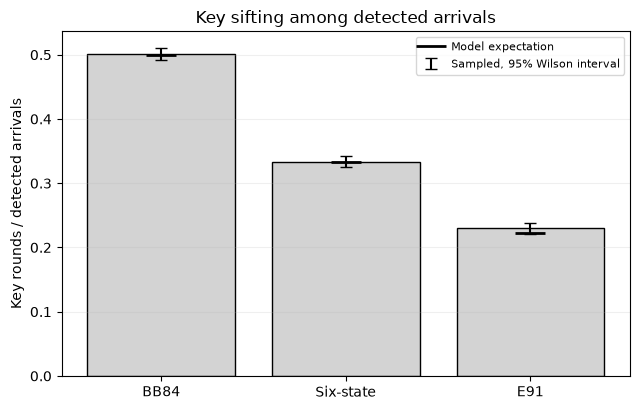

In [402]:
comparison_baseline = comparison_experiment(
    comparison_fixed_distance, comparison_fixed_noise, 0, 0
)

print(
    f"Reference: L = {comparison_fixed_distance:g} km, "
    f"p = {comparison_fixed_noise:g}"
)
print(
    f"{'Protocol':<12} {'Attempts':>10} {'Arrivals':>10} "
    f"{'Key':>8} {'Public test':>12} {'Candidates':>12} {'QBER test':>11}"
)

for name, row in comparison_baseline.items():
    print(
        f"{name:<12} {row['attempts']:>10} {row['arrived']:>10} "
        f"{row['key']:>8} {row['tested']:>12} "
        f"{row['candidates']:>12} {row['qber']:>11.2%}"
    )

names = list(comparison_protocols)
positions = np.arange(len(names))
values = np.array([comparison_baseline[n]["sifting"] for n in names])
low = np.array([comparison_baseline[n]["sifting_low"] for n in names])
high = np.array([comparison_baseline[n]["sifting_high"] for n in names])

fig, ax = plt.subplots(figsize=(6.5, 4.2))

ax.bar(positions, values, color="lightgray", edgecolor="black")
ax.errorbar(
    positions, values,
    yerr=np.vstack((values - low, high - values)),
    fmt="none", ecolor="black", capsize=4,
    label="Sampled, 95% Wilson interval"
)
ax.plot(
    positions,
    [comparison_protocols[n]["sift"] for n in names],
    "_", color="black", markersize=22, markeredgewidth=2,
    label="Model expectation"
)

ax.set_xticks(positions, names)
ax.set_ylabel("Key rounds / detected arrivals")
ax.set_title("Key sifting among detected arrivals")
ax.set_ylim(bottom=0)
ax.grid(axis="y", alpha=0.2)
ax.legend(fontsize=8)

fig.tight_layout()
plt.show()

In [405]:
resource_table = {}

for protocol, row in comparison_baseline.items():
    attempts = row["attempts"]
    candidates = row["candidates"]
    chsh_rounds = int(np.sum(row["chsh_counts"]))

    resource_table[protocol] = {
        "Transmission attempts": attempts,
        "Qubits prepared (ideal source)": attempts * (2 if protocol == "E91" else 1),
        "Traveling qubits": attempts,
        "Lost traveling qubits": attempts - row["arrived"],
        "Detected arrivals": row["arrived"],
        "Discarded settings": row["arrived"] - row["key"] - chsh_rounds,
        "CHSH test rounds": chsh_rounds,
        "Sifted key bits before testing": row["key"],
        "Publicly revealed key bits": row["tested"],
        "Remaining candidate bits": candidates,
        "Link attempts per candidate bit":
            attempts / candidates if candidates else np.nan,
    }

print(f"{'Resource / round count':<36}", end="")
for protocol in resource_table:
    print(f"{protocol:>15}", end="")
print()

for metric in resource_table["BB84"]:
    print(f"{metric:<36}", end="")
    for protocol in resource_table:
        value = resource_table[protocol][metric]
        text = f"{value:,.2f}" if isinstance(value, float) else f"{value:,}"
        print(f"{text:>15}", end="")
    print()

Resource / round count                         BB84      Six-state            E91
Transmission attempts                       100,000        100,000        100,000
Qubits prepared (ideal source)              100,000        100,000        200,000
Traveling qubits                            100,000        100,000        100,000
Lost traveling qubits                        90,190         90,011         89,897
Detected arrivals                             9,810          9,989         10,103
Discarded settings                            4,895          6,655          3,333
CHSH test rounds                                  0              0          4,449
Sifted key bits before testing                4,915          3,334          2,321
Publicly revealed key bits                      980            661            458
Remaining candidate bits                      3,935          2,673          1,863
Link attempts per candidate bit               25.41          37.41          53.68


## Cell 6 Compare public-sample QBER versus noise

For every noise point, rerun all protocols with the same distance and source-attempt budget. The solid line is $Q=p/2$; the markers use revealed key samples. Under isotropic depolarization, all three key-round QBERs have the same expectation. E91 and six-state retain fewer key rounds, so their public estimates generally have wider intervals. Matching means do not make their sifting efficiencies or key-rate formulas identical.

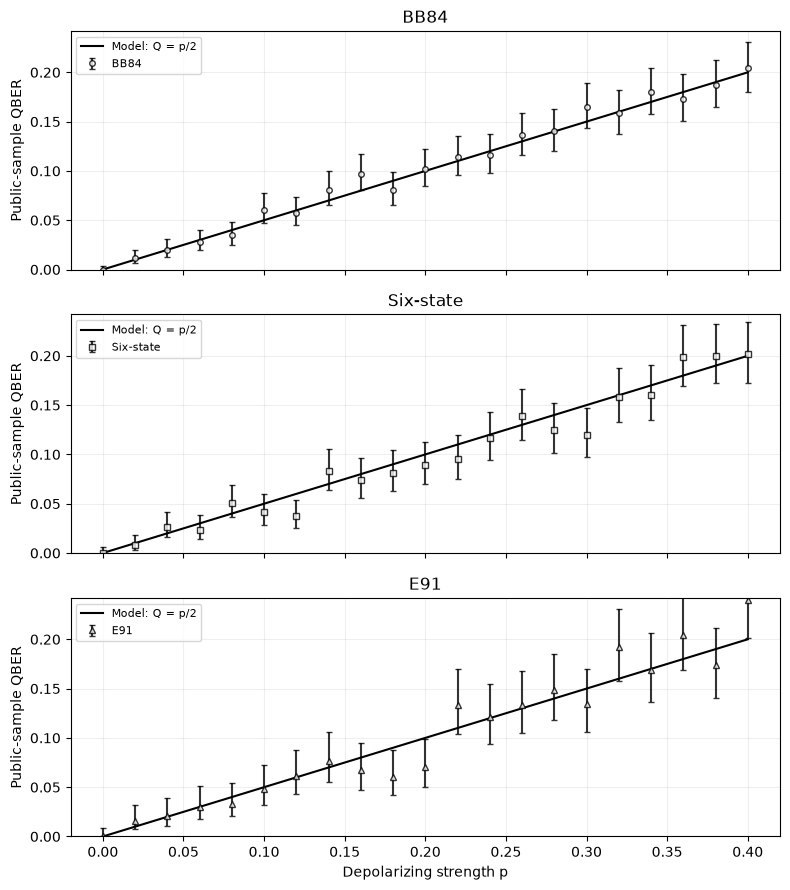

In [403]:
comparison_noise_results = [
    comparison_experiment(comparison_fixed_distance, float(p), 1, index)
    for index, p in enumerate(comparison_noise_values)
]

fig, axes = plt.subplots(
    3, 1, figsize=(8, 9), sharex=True, sharey=True
)

for ax, protocol in zip(axes, comparison_protocols):
    ax.plot(
        comparison_noise_values,
        comparison_noise_values / 2,
        color="black", label="Model: Q = p/2"
    )

    comparison_errorbar(
        ax,
        comparison_noise_values,
        [result[protocol] for result in comparison_noise_results],
        "qber",
        protocol
    )

    ax.set_title(protocol)
    ax.set_ylabel("Public-sample QBER")
    ax.set_ylim(bottom=0)
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)

axes[-1].set_xlabel("Depolarizing strength p")
fig.tight_layout()
plt.show()

## Cell 7 Check the effect of distance on arrivals and QBER

Now change distance while keeping p = 0.1. All protocols have the same expected arrival fraction $T(L)$ because one traveling qubit crosses the same fiber per attempt. QBER among key rounds stays at $p/2$ in expectation: this model does not automatically make p grow with distance. Longer links give fewer public test bits and less precise estimates. Loss is not counted as a wrong bit.

The left axis uses a logarithmic scale to show small arrival fractions. The right panel uses the public samples and 95% Wilson intervals, including a nonzero upper interval when no errors happen to be observed.

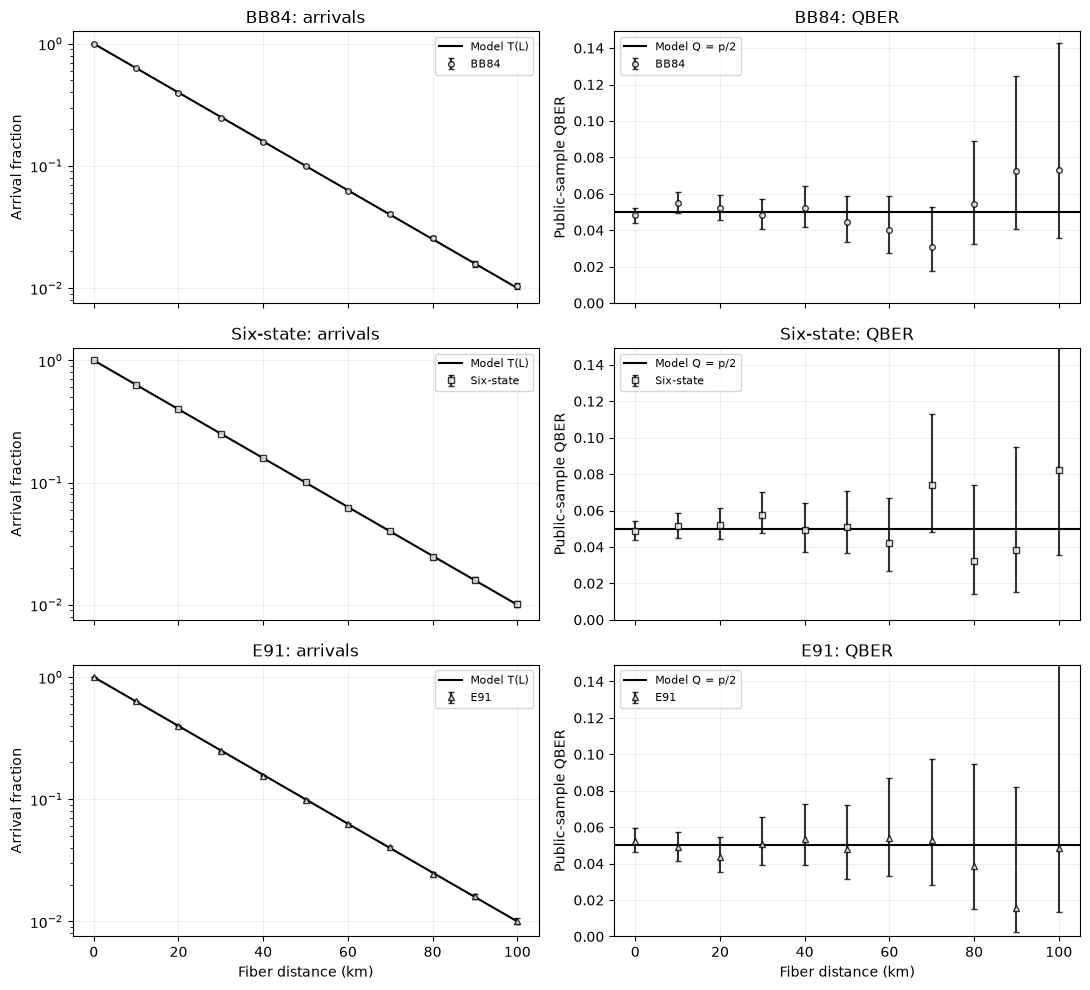

In [404]:
comparison_distance_results = [
    comparison_experiment(float(distance), comparison_fixed_noise, 2, index)
    for index, distance in enumerate(comparison_distances)
]

comparison_T_curve = np.array([
    transmission_probability(float(distance), comparison_alpha)
    for distance in comparison_distances
])

fig, axes = plt.subplots(
    3, 2, figsize=(11, 10), sharex=True, sharey="col"
)

for row, protocol in enumerate(comparison_protocols):
    results = [
        result[protocol] for result in comparison_distance_results
    ]

    # Left: arrival fraction
    ax = axes[row, 0]
    ax.plot(
        comparison_distances, comparison_T_curve,
        color="black", label="Model T(L)"
    )
    comparison_errorbar(
        ax, comparison_distances, results, "arrival", protocol
    )
    ax.set_yscale("log")
    ax.set_title(f"{protocol}: arrivals")
    ax.set_ylabel("Arrival fraction")

    # Right: public-sample QBER
    ax = axes[row, 1]
    ax.axhline(
        comparison_fixed_noise / 2,
        color="black", label="Model Q = p/2"
    )
    comparison_errorbar(
        ax, comparison_distances, results, "qber", protocol
    )
    ax.set_title(f"{protocol}: QBER")
    ax.set_ylabel("Public-sample QBER")
    ax.set_ylim(bottom=0)

for ax in axes.flat:
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)

for ax in axes[-1]:
    ax.set_xlabel("Fiber distance (km)")

fig.tight_layout()
plt.show()

## Cell 8 Define the common rate accounting and compare rates versus distance

We reuse the protocol-specific fractions from Section 3 under the same trusted, calibrated, isotropic channel and ideal one-way processing assumptions:

$$r_{84}=\max(0,1-2h_2(Q)),\qquad r_6=\max(0,1-H_4(1-3Q/2,Q/2,Q/2,Q/2)).$$

For this E91 benchmark, $r_E=r_{84}$ when the modeled CHSH value exceeds 2, and zero otherwise. This is an entanglement-based BB84 fraction specialized to the assumed channel, with the E91 Bell-test condition. It is not a general E91 or device-independent rate inferred from S alone. The protocols use the same trust level; E91 receives no unproved security bonus.

Let s be the protocol's key sifting fraction and f the common public-test fraction. We display both:

$$R_\infty=Tsr,\qquad R_{\rm budget}=(1-f)Tsr.$$

Section 3's $R_\infty$ ignores the finite public-test sacrifice for every protocol. Here the **plotted curves use $R_{\rm budget}$**, applying the same 20% key-test budget to all three. This is large-sample accounting, not an exact finite-run key length; per-group integer rounding is visible in the actual counts. E91's 2/9 factor already excludes CHSH rounds, so they must not be subtracted a second time.

Both rates omit finite-key security penalties and authentication costs and assume ideal reconciliation/privacy amplification without implementing them. Units are model secret bits per attempted link use, not bits per second. Under pure attenuation with fixed nonzero secret fraction and no dark counts, the model predicts exponential decay rather than a sharp maximum distance.

Reference-point model benchmarks (bits per attempted link use)
Protocol       Secret fraction     R infinity    R with test budget
BB84                   0.42721       0.021360              0.017088
Six-state              0.49682       0.016561              0.013248
E91                    0.42721       0.009493              0.007595


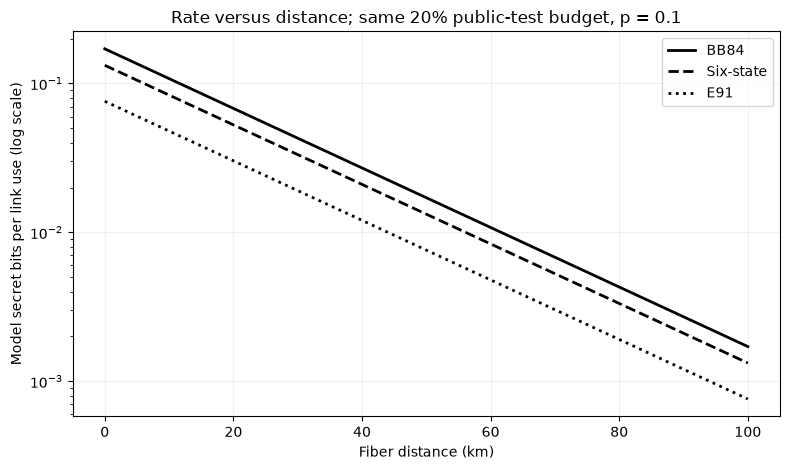

In [397]:
def comparison_model_metrics(protocol, distance_km, p):
    if protocol not in comparison_protocols or not np.isfinite(p) or not 0 <= p <= 1:
        raise ValueError("Use a known protocol and noise strength in [0, 1].")
    q = p / 2
    s_value = 2 * np.sqrt(2) * (1 - p)
    if protocol == "Six-state":
        fraction = six_secret_fraction(q)
    elif protocol == "E91":
        fraction = e91_calibrated_fraction(q, s_value)
    else:
        fraction = max(0.0, 1 - 2 * binary_entropy(q))
    transmission = transmission_probability(distance_km, comparison_alpha)
    rate = transmission * comparison_protocols[protocol]["sift"] * fraction
    return {"qber": q, "fraction": fraction, "rate_asymptotic": rate,
            "rate_test_budget": (1 - comparison_test_fraction) * rate}

print("Reference-point model benchmarks (bits per attempted link use)")
print(f"{'Protocol':<12} {'Secret fraction':>17} {'R infinity':>14} {'R with test budget':>21}")
for comparison_protocol in comparison_protocols:
    comparison_model = comparison_model_metrics(comparison_protocol, comparison_fixed_distance, comparison_fixed_noise)
    print(f"{comparison_protocol:<12} {comparison_model['fraction']:>17.5f} "
          f"{comparison_model['rate_asymptotic']:>14.6f} {comparison_model['rate_test_budget']:>21.6f}")

comparison_distance_dense = np.linspace(comparison_distances[0], comparison_distances[-1], 201)
comparison_fig, comparison_ax = plt.subplots(figsize=(8, 4.8))
for comparison_protocol in comparison_protocols:
    comparison_rates = [comparison_model_metrics(comparison_protocol, float(d), comparison_fixed_noise)["rate_test_budget"]
                        for d in comparison_distance_dense]
    comparison_ax.plot(comparison_distance_dense, comparison_rates, color="black",
                       linestyle=comparison_styles[comparison_protocol], linewidth=2, label=comparison_protocol)
comparison_ax.set_yscale("log")
comparison_ax.set(xlabel="Fiber distance (km)",
    ylabel="Model secret bits per link use (log scale)",
    title=f"Rate versus distance; same {comparison_test_fraction:.0%} public-test budget, p = {comparison_fixed_noise:g}")
comparison_ax.grid(alpha=0.2)
comparison_ax.legend()
comparison_fig.tight_layout()
plt.show()

## Cell 9 Compare secret fractions and rates versus noise

The left panel shows model secret bits per unrevealed key-round bit, before transmission and sifting losses. The right panel includes those losses and the common public-test budget at the fixed distance. This separates noise tolerance from sifting efficiency.

For the selected model, E91's secret-fraction curve overlaps BB84's while its net rate differs because 2/9 of detected pairs become key rounds instead of 1/2. Six-state can have a larger secret fraction and tolerate more noise, but its 1/3 sifting factor reduces its rate at low noise. Any crossing or ranking shown is conditional on these settings and this security benchmark, not a universal hardware ranking. These are model curves, not sample-based finite-key acceptance decisions.

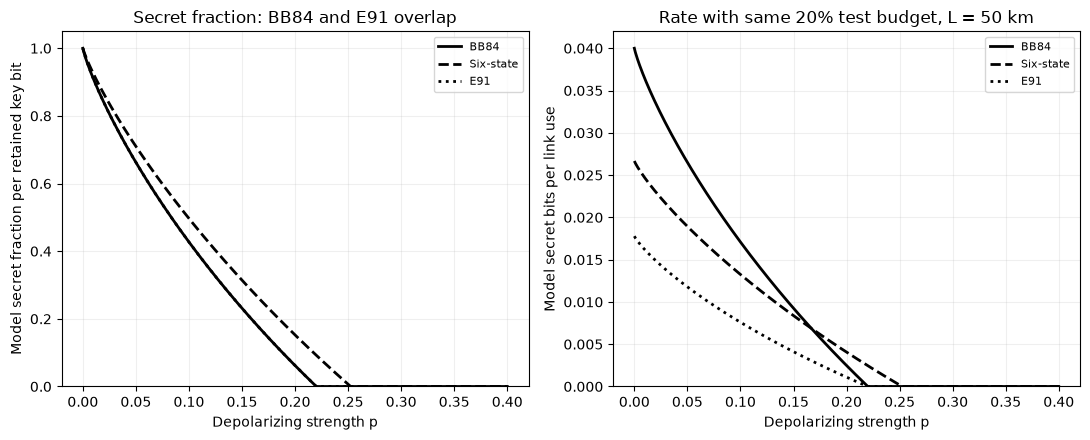

In [398]:
comparison_noise_dense = np.linspace(0.0, comparison_noise_values[-1], 401)
comparison_fig, comparison_axes = plt.subplots(1, 2, figsize=(11, 4.5))
for comparison_protocol in comparison_protocols:
    comparison_models = [comparison_model_metrics(comparison_protocol, comparison_fixed_distance, float(p))
                         for p in comparison_noise_dense]
    comparison_axes[0].plot(comparison_noise_dense, [row["fraction"] for row in comparison_models],
        color="black", linestyle=comparison_styles[comparison_protocol], linewidth=2, label=comparison_protocol)
    comparison_axes[1].plot(comparison_noise_dense, [row["rate_test_budget"] for row in comparison_models],
        color="black", linestyle=comparison_styles[comparison_protocol], linewidth=2, label=comparison_protocol)
comparison_axes[0].set(ylabel="Model secret fraction per retained key bit",
                      title="Secret fraction: BB84 and E91 overlap")
comparison_axes[1].set(ylabel="Model secret bits per link use",
                      title=f"Rate with same {comparison_test_fraction:.0%} test budget, L = {comparison_fixed_distance:g} km")
for comparison_ax in comparison_axes:
    comparison_ax.set_xlabel("Depolarizing strength p")
    comparison_ax.set_ylim(bottom=0)
    comparison_ax.grid(alpha=0.2)
    comparison_ax.legend(fontsize=8)
comparison_fig.tight_layout()
plt.show()

## References for the protocol and rate models

- Course: updated Lecture 6, E91 measurement settings on slide 16.
- A. K. Ekert, *Quantum cryptography based on Bell's theorem*, Physical Review Letters 67, 661 (1991). https://doi.org/10.1103/PhysRevLett.67.661
- G. Murta et al., *Key rates for quantum key distribution protocols with asymmetric noise*, Physical Review A 101, 062321 (2020), Eqs. (2)–(4). https://doi.org/10.1103/PhysRevA.101.062321
- NIST/SEMATECH e-Handbook of Statistical Methods, Section 7.2.4.1, *Confidence intervals* (Wilson intervals for proportions). https://www.itl.nist.gov/div898/handbook/prc/section2/prc241.htm

The rate equations above specialize the trusted qubit model to symmetric depolarizing noise. The E91 demonstration additionally requires a Bell violation; its rate is not a generic bound derived from CHSH alone.